In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import tqdm as tqdm
import sklearn 

from scipy.integrate import simpson
from sklearn.preprocessing import StandardScaler

In [9]:
#load data
import pickle
with open(r"/data/keeling/a/cstraus2/Phd_research/normalized_entropies_scale1_bw15_gridn31_masked_ptot_rounded_trivariate_normadj.pkl", "rb") as f:
   Entropy_data = pickle.load(f)

MIs = pd.read_csv('MIs_scale1_bw15_gridn_31_normadj.csv', index_col = 0)
trivar_MI = pd.read_csv('triMI_scale1_bw15_gridn_31_normadj.csv',index_col = 0)

In [51]:
brw_tri = trivar_MI.loc[trivar_MI['station'] == 'brw'].copy().reset_index(drop=True)
brw_tri

,station,MI_label,Interacting_information,Total_shared_information,Z_Conditioned_jointMI,H(x),H(y),H(z),C_tz
0,brw,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,0.021,0.232,0.214,individual_entropy_Avg_Precipitation_rate_in,individual_entropy_Prior_sm_100,individual_entropy_Delta_sm_10,0.062
1,brw,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,0.014,0.249,0.231,individual_entropy_Avg_Precipitation_rate_in,individual_entropy_Prior_sm_100,individual_entropy_Delta_sm_100,0.084
2,brw,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,0.008,0.077,0.059,individual_entropy_Avg_Precipitation_rate_in,individual_entropy_Prior_sm_100,individual_entropy_Delta_sm_100_perPtot,0.028
3,brw,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,0.011,0.075,0.057,individual_entropy_Avg_Precipitation_rate_in,individual_entropy_Prior_sm_100,individual_entropy_Delta_sm_10_perPtot,0.020
4,brw,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,0.014,0.245,0.223,individual_entropy_Avg_Precipitation_rate_in,individual_entropy_Prior_sm_10,individual_entropy_Delta_sm_10,0.064
5,brw,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,0.006,0.253,0.231,individual_entropy_Avg_Precipitation_rate_in,individual_entropy_Prior_sm_10,individual_entropy_Delta_sm_100,0.084
6,brw,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,0.007,0.080,0.058,individual_entropy_Avg_Precipitation_rate_in,individual_entropy_Prior_sm_10,individual_entropy_Delta_sm_100_perPtot,0.028
7,brw,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,0.010,0.083,0.061,individual_entropy_Avg_Precipitation_rate_in,individual_entropy_Prior_sm_10,individual_entropy_Delta_sm_10_perPtot,0.021
8,brw,trivariate_MI_Median_Precipitation_rate_in_Pri...,0.017,0.144,0.128,individual_entropy_Median_Precipitation_rate_in,individual_entropy_Prior_sm_100,individual_entropy_Delta_sm_10,0.037
9,brw,trivariate_MI_Median_Precipitation_rate_in_Pri...,0.015,0.163,0.147,individual_entropy_Median_Precipitation_rate_in,individual_entropy_Prior_sm_100,individual_entropy_Delta_sm_100,0.053


Following Goodwell and Kumar 2017 a and b:
I(x;y) = U(x;y) + R(x,z:y)
I(z;y) = U(z;y) + R(x,z;y)


R will be Rs, the Rescaled Redundancy measure
Rs = Rmin +Is*(Rmmi-Rmin)

where Is is the normalized source dependency
Is=I(x;z)/min[H(x), H(z)]

Rmmi = min(I(x;y), I(z;y))
Rmin = max[0,-II] where II is I(x;z;y) = S-R

In [52]:
def MI_partitioning(Entropies, MI, tri_MI):
    stations = list(MI.station.unique())
    Partitions = []
    for s in stations:
        print(s)
        station_entropies = Entropies[s].copy().reset_index(drop=True)
        station_MI = MI.loc[MI['station'] == s].copy().reset_index(drop=True)
        station_triMI = tri_MI.loc[tri_MI['station'] == s].copy().reset_index(drop=True)
        
        for i in range(len(station_triMI)):
            x_var_label = station_triMI.loc[i, 'H(x)'].removeprefix('individual_entropy_')
            y_var_label = station_triMI.loc[i, 'H(y)'].removeprefix('individual_entropy_')
            z_var_label = station_triMI.loc[i, 'H(z)'].removeprefix('individual_entropy_')
            tri_mi_label = station_triMI.loc[i, 'MI_label']

            II = station_triMI.loc[i, 'Interacting_information']
            T_MI = station_triMI.loc[i, 'Total_shared_information']
            Z_conditioned_MI = station_triMI.loc[i, 'Z_Conditioned_jointMI']
            #z is the target variable of delta sm pep Ptot
            str_p1 = f"(?:{x_var_label}.*{y_var_label}|{y_var_label}.*{x_var_label})"
            xy_MI = station_MI.loc[station_MI['MI_label'].str.contains(str_p1, regex = True), 
                                                                'mutual_information'].iloc[0]

            str_p2 = f"(?:{z_var_label}.*{y_var_label}|{y_var_label}.*{z_var_label})"
            yz_MI = station_MI.loc[station_MI['MI_label'].str.contains(str_p2,  regex = True), 
                                                                'mutual_information'].iloc[0]
            
            str_p3 = f"(?:{z_var_label}.*{x_var_label}|{x_var_label}.*{z_var_label})"
            xz_MI = station_MI.loc[station_MI['MI_label'].str.contains(str_p3, regex = True), 
                                                                'mutual_information'].iloc[0]
            
            Hx_column_name = station_entropies.columns[station_entropies.columns.str.contains(x_var_label)
                                           & ~station_entropies.columns.str.contains('^joint')
                                           & ~station_entropies.columns.str.contains('^trivariate')]
            
            Hx = station_entropies[Hx_column_name[0]].iloc[0]
            
            Hy_column_name = station_entropies.columns[station_entropies.columns.str.contains(y_var_label)
                                           & ~station_entropies.columns.str.contains('^joint')
                                           & ~station_entropies.columns.str.contains('^trivariate')]
            
            Hy = station_entropies[Hy_column_name[0]].iloc[0]

            Hz_column_name = station_entropies.columns[station_entropies.columns.str.contains(z_var_label)
                                           & ~station_entropies.columns.str.contains('^joint')
                                           & ~station_entropies.columns.str.contains('^trivariate')]
            
            Hz = station_entropies[Hz_column_name[0]].iloc[0]


            Rmmi = np.min([yz_MI, xz_MI])
            
            Is = xy_MI/(np.min([Hx, Hy]))

            Rmin = np.max([0, -II])
            Rs = Rmin + Is*(Rmmi - Rmin)
            
            Ux = xz_MI - Rs
            Uy = yz_MI - Rs

            Syn = II + Rs
            if Syn < 0 and Syn > -0.001:
                Syn = 0

            Rsz = Rs/Z_conditioned_MI
            Uxz = Ux/Z_conditioned_MI
            Uyz = Uy/Z_conditioned_MI
            Syn_z = Syn/Z_conditioned_MI
            # add label 
            Partitions.append({
                "Station": s,
                "MI_label": tri_mi_label,
                "Tri_II": II,
                "Total_tri_MI": T_MI,
                "MI_xy": xy_MI,
                "MI_xz": xz_MI,
                "MI_yz": yz_MI,
                "X_var": x_var_label,
                "Unique_x": Ux,
                "Y_var": y_var_label,
                "Unique_y": Uy,
                "Z_var": z_var_label,
                "Redundancy": Rs,
                "Redundancy_zratio": Rsz,
                "Unique_xz_ratio": Uxz, 
                "Unique_yz_ratio": Uyz,
                "Synergistic": Syn,
                "Synergistic_ratio": Syn_z,
                "Is": Is, 
                "Rmmi": Rmmi,
                "Rmin":Rmin


            })
            

    return pd.DataFrame(Partitions)

In [53]:
Partition_values = MI_partitioning(Entropy_data, MIs, trivar_MI)

bbc
brw
bvl
cmi
dek
dxs
fai
fre
frm
icc
llc
mon
oln
orr
rnd
sfm
siu
sni
stc
ste


In [54]:
Partition_values.loc[Partition_values['Tri_II'] < 0]

,Station,MI_label,Tri_II,Total_tri_MI,MI_xy,MI_xz,MI_yz,X_var,Unique_x,Y_var,...,Z_var,Redundancy,Redundancy_zratio,Unique_xz_ratio,Unique_yz_ratio,Synergistic,Synergistic_ratio,Is,Rmmi,Rmin
2,bbc,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,-8.881784e-16,0.066,0.013,0.030,0.023,Avg_Precipitation_rate_in,0.029882,Prior_sm_100,...,Delta_sm_100_perPtot,0.000118,0.002223,0.563815,0.431739,0.000118,0.002223,0.005122,0.023,8.881784e-16
366,orr,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,-8.881784e-16,0.106,0.031,0.023,0.052,Avg_Precipitation_rate_in,0.022713,Prior_sm_100,...,Delta_sm_100_perPtot,0.000287,0.003826,0.302841,0.689508,0.000287,0.003826,0.012475,0.023,8.881784e-16
370,orr,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,-4.440892e-16,0.092,0.031,0.023,0.052,Avg_Precipitation_rate_in,0.022713,Prior_sm_10,...,Delta_sm_100_perPtot,0.000287,0.004282,0.339001,0.771837,0.000287,0.004282,0.012475,0.023,4.440892e-16
382,orr,trivariate_MI_Peak_Precipitation_rate_in_Prior...,-3.000000e-03,0.124,0.026,0.049,0.052,Peak_Precipitation_rate_in,0.045625,Prior_sm_100,...,Delta_sm_100_perPtot,0.003375,0.034442,0.465558,0.496171,0.000375,0.003829,0.008158,0.049,3.000000e-03
426,sfm,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,-1.000000e-03,0.145,0.038,0.038,0.044,Avg_Precipitation_rate_in,0.036527,Prior_sm_10,...,Delta_sm_100_perPtot,0.001473,0.016189,0.401393,0.467327,0.000473,0.005200,0.012790,0.038,1.000000e-03
430,sfm,trivariate_MI_Median_Precipitation_rate_in_Pri...,-3.552714e-15,0.090,0.030,0.016,0.044,Median_Precipitation_rate_in,0.015839,Prior_sm_100,...,Delta_sm_100_perPtot,0.000161,0.002684,0.263983,0.730650,0.000161,0.002684,0.010064,0.016,3.552714e-15
434,sfm,trivariate_MI_Median_Precipitation_rate_in_Pri...,-1.000000e-03,0.106,0.030,0.016,0.044,Median_Precipitation_rate_in,0.014849,Prior_sm_10,...,Delta_sm_100_perPtot,0.001151,0.016681,0.215204,0.621001,0.000151,0.002188,0.010064,0.016,1.000000e-03
437,sfm,trivariate_MI_Peak_Precipitation_rate_in_Prior...,-1.400000e-02,1.058,0.087,0.929,0.056,Peak_Precipitation_rate_in,0.913852,Prior_sm_100,...,Delta_sm_100,0.015148,0.015601,0.941145,0.042072,0.001148,0.001183,0.027341,0.056,1.400000e-02
440,sfm,trivariate_MI_Peak_Precipitation_rate_in_Prior...,-1.500000e-02,0.966,0.087,0.843,0.040,Peak_Precipitation_rate_in,0.827316,Prior_sm_10,...,Delta_sm_10,0.015684,0.017622,0.929569,0.027322,0.000684,0.000768,0.027341,0.040,1.500000e-02
442,sfm,trivariate_MI_Peak_Precipitation_rate_in_Prior...,-1.000000e-03,0.207,0.087,0.078,0.044,Peak_Precipitation_rate_in,0.075824,Prior_sm_10,...,Delta_sm_100_perPtot,0.002176,0.016608,0.578812,0.319270,0.001176,0.008975,0.027341,0.044,1.000000e-03


In [8]:
#basic stats for each combination across all the station data
numeric_cols = Partition_values.select_dtypes(include="number").columns.tolist()
string_cols = [c for c in Partition_values.columns if c not in numeric_cols and c != "MI_label"]

agg_dict = {col: ["mean", "min", "max"] for col in numeric_cols}
for col in string_cols:
    agg_dict[col] = "first"   # just keep one representative string


agg_df = (
    Partition_values.groupby("MI_label", as_index=False)
      .agg(agg_dict)
)

agg_df.columns = [
    col if isinstance(col, str) else f"{col[0]}_{col[1]}"
    for col in agg_df.columns.to_flat_index()
]

In [9]:
agg_df

,MI_label_,Tri_II_mean,Tri_II_min,Tri_II_max,Total_tri_MI_mean,Total_tri_MI_min,Total_tri_MI_max,MI_xy_mean,MI_xy_min,MI_xy_max,...,Synergistic_mean,Synergistic_min,Synergistic_max,Synergistic_ratio_mean,Synergistic_ratio_min,Synergistic_ratio_max,Station_first,X_var_first,Y_var_first,Z_var_first
0,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,-0.01700,-0.032,-4.000000e-03,0.25550,0.187,0.363,0.01995,0.013,0.038,...,0.000484,-1.878551e-04,0.001285,0.000133,-5.374967e-05,0.000355,bbc,Avg_Precipitation_rate_in,Prior_sm_100,Delta_sm_10
1,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,-0.01670,-0.031,-5.000000e-03,0.23995,0.165,0.335,0.01995,0.013,0.038,...,0.000401,-1.225142e-04,0.000961,0.000125,-3.689076e-05,0.000333,bbc,Avg_Precipitation_rate_in,Prior_sm_100,Delta_sm_100
2,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,-0.00490,-0.013,-8.881784e-16,0.08555,0.056,0.120,0.01995,0.013,0.038,...,0.000163,4.327535e-05,0.000486,0.000070,1.792682e-05,0.000181,bbc,Avg_Precipitation_rate_in,Prior_sm_100,Delta_sm_100_perPtot
3,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,-0.01220,-0.019,-5.000000e-03,0.10030,0.068,0.142,0.01995,0.013,0.038,...,0.000098,7.178751e-06,0.000371,0.000034,2.228734e-06,0.000135,bbc,Avg_Precipitation_rate_in,Prior_sm_100,Delta_sm_10_perPtot
4,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,-0.01425,-0.027,8.881784e-16,0.30675,0.231,0.430,0.01995,0.013,0.038,...,0.000509,-1.470170e-04,0.001272,0.000140,-4.206496e-05,0.000352,bbc,Avg_Precipitation_rate_in,Prior_sm_10,Delta_sm_10
5,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,-0.01530,-0.024,-6.000000e-03,0.22745,0.152,0.318,0.01995,0.013,0.038,...,0.000411,-6.534091e-05,0.000948,0.000127,-1.967507e-05,0.000316,bbc,Avg_Precipitation_rate_in,Prior_sm_10,Delta_sm_100
6,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,-0.00470,-0.009,1.000000e-03,0.07920,0.055,0.145,0.01995,0.013,0.038,...,0.000214,5.048791e-05,0.001486,0.000089,2.091463e-05,0.000554,bbc,Avg_Precipitation_rate_in,Prior_sm_10,Delta_sm_100_perPtot
7,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,-0.01310,-0.022,-4.000000e-03,0.10370,0.070,0.138,0.01995,0.013,0.038,...,0.000091,5.571031e-06,0.000384,0.000031,1.824773e-06,0.000140,bbc,Avg_Precipitation_rate_in,Prior_sm_10,Delta_sm_10_perPtot
8,trivariate_MI_Median_Precipitation_rate_in_Pri...,-0.01215,-0.023,-3.000000e-03,0.14795,0.093,0.253,0.01850,0.012,0.030,...,0.000149,-1.056093e-04,0.000387,0.000041,-3.021725e-05,0.000103,bbc,Median_Precipitation_rate_in,Prior_sm_100,Delta_sm_10
9,trivariate_MI_Median_Precipitation_rate_in_Pri...,-0.01175,-0.024,-5.000000e-03,0.12905,0.088,0.219,0.01850,0.012,0.030,...,0.000140,-6.499033e-05,0.000355,0.000042,-1.956951e-05,0.000106,bbc,Median_Precipitation_rate_in,Prior_sm_100,Delta_sm_100


# Plot dual nMI violin plots
## plot the C_xy value (Delta_sm entropy is the denom)
## plot the delta_Ptot 

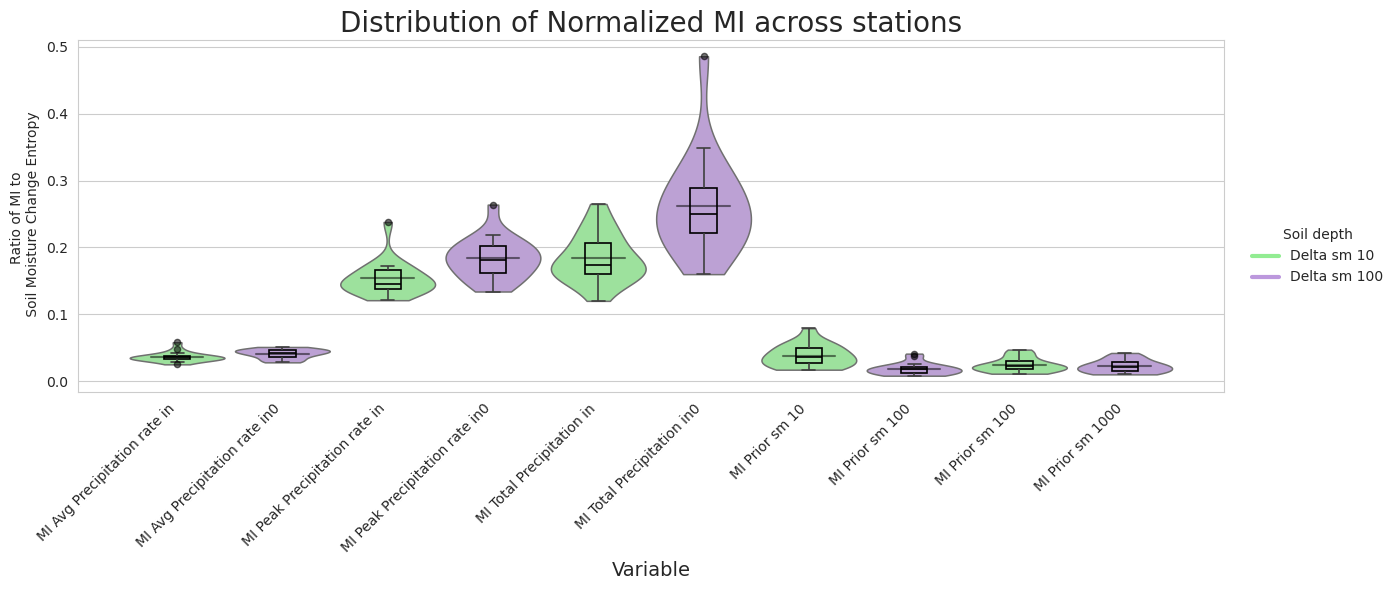

In [69]:
# Visualize station-level c_xy distributions for selected MI labels
selected_label_pairs = [
    ("MI_Avg_Precipitation_rate_in_and_Delta_sm_10", "MI_Avg_Precipitation_rate_in_and_Delta_sm_100"),
    ("MI_Peak_Precipitation_rate_in_and_Delta_sm_10", "MI_Peak_Precipitation_rate_in_and_Delta_sm_100"),
    ("MI_Total_Precipitation_in_and_Delta_sm_10", "MI_Total_Precipitation_in_and_Delta_sm_100"),
    ("MI_Prior_sm_10_and_Delta_sm_10", "MI_Prior_sm_10_and_Delta_sm_100"),
    ("MI_Prior_sm_100_and_Delta_sm_10", "MI_Prior_sm_100_and_Delta_sm_100"),
]
selected_labels = [label for pair in selected_label_pairs for label in pair]

def make_display_label(label: str) -> str:
    stripped = label.replace("_and_Delta_sm_10", "").replace("_and_Delta_sm_100", "")
    stripped = stripped.replace("MI_", "MI ")
    return stripped.replace("_", " ")

display_label_map = {label: make_display_label(label) for label in selected_labels}

plot_df = (
    MIs.loc[(MIs["MI_label"].isin(selected_labels)) & (~MIs["station"].isin(["bbc", "sni"])), ["station", "MI_label", "C_xy"]]
        .copy()
)

plot_df["delta_depth"] = plot_df["MI_label"].apply(
    lambda label: "Delta_sm_100" if "Delta_sm_100" in label else "Delta_sm_10"
)
plot_df["plot_label"] = pd.Categorical(plot_df["MI_label"], categories=selected_labels, ordered=True)
plot_df["display_label"] = plot_df["plot_label"].map(display_label_map)

palette_map = {"Delta_sm_10": "#92ec92", "Delta_sm_100": "#bc98dd"}
hue_order = ["Delta_sm_10", "Delta_sm_100"]

sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(14, 6))
sns.violinplot(
    data=plot_df,
    x="plot_label",
    y="C_xy",
    order=selected_labels,
    hue="delta_depth",
    hue_order=hue_order,
    palette=palette_map,
    dodge=False,
    cut=0,
    inner=None,
    linewidth=1.1,
    width=0.9,
    density_norm= 'width',
    ax=ax,
)

sns.boxplot(
    data=plot_df,
    x="plot_label",
    y="C_xy",
    order=selected_labels,
    width=0.25,
    showcaps=True,
    boxprops={"facecolor": "none", "edgecolor": "black", "linewidth": 1.2},
    whiskerprops={"linewidth": 1.2},
    capprops={"linewidth": 1.2},
    medianprops={"linewidth": 1.2, "color": "black"},
    showfliers=True,
    flierprops={"marker": "o", "markersize": 4.5, "markerfacecolor": "black", "markeredgecolor": "black", "alpha": 0.55},
    dodge=False,
    ax=ax,
)

mean_values = (
    plot_df.groupby("plot_label", observed=False)["C_xy"]
           .mean()
           .reindex(selected_labels)
)
for x_pos, mean_val in zip(range(len(selected_labels)), mean_values):
    ax.plot([x_pos - 0.25, x_pos + 0.25], [mean_val, mean_val], color="black", linewidth=1.5, alpha=0.5)

if ax.legend_ is not None:
    ax.legend_.remove()
legend_handles = [
    plt.Line2D([0], [0], color=palette_map[key], lw=3, label=key.replace("_", " "))
    for key in hue_order
]
ax.legend(handles=legend_handles, title="Soil depth", title_fontsize = 10, fontsize = 10, frameon=False, bbox_to_anchor = (1.15, 0.5) )
ax.set_xticks(range(len(selected_labels)))
ax.set_xticklabels([display_label_map[label] for label in selected_labels], rotation=45, ha="right")
ax.set_xlabel("Variable", fontsize =14)
ax.set_ylabel("Ratio of MI to \n Soil Moisture Change Entropy")
ax.set_title("Distribution of Normalized MI across stations", fontsize =20)
plt.tight_layout()
plt.show()


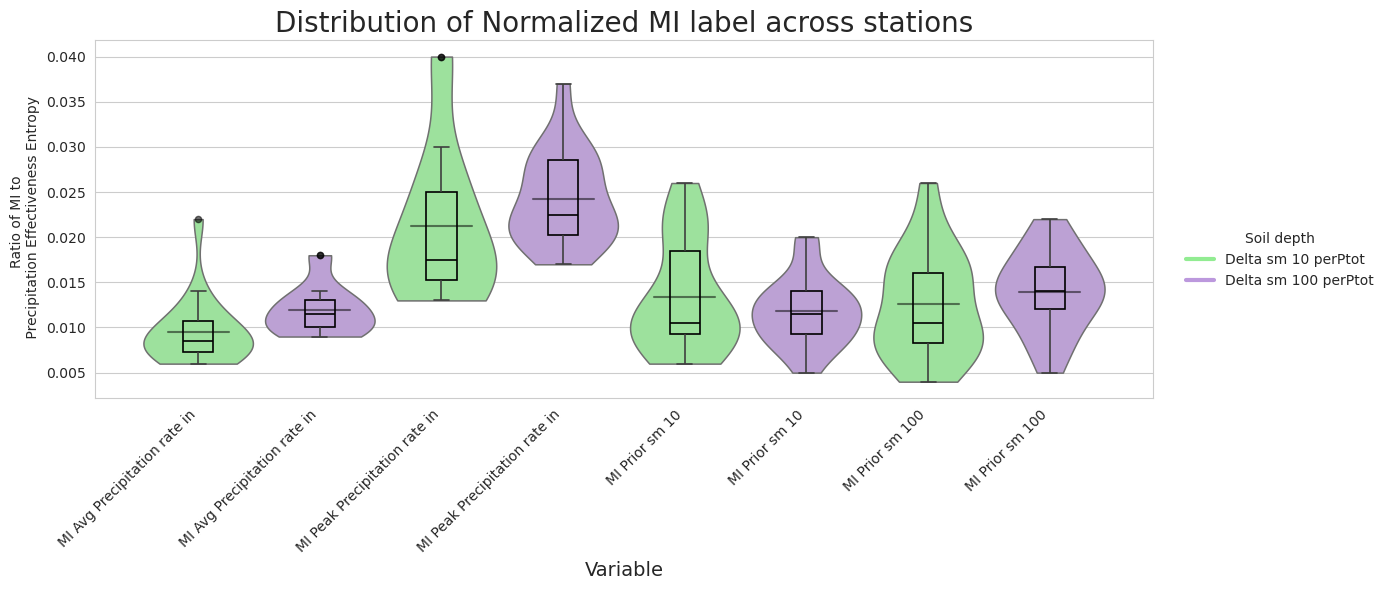

In [68]:
# Visualize station-level c_xy distributions for selected MI labels
selected_label_pairs = [
    ("MI_Avg_Precipitation_rate_in_and_Delta_sm_10_perPtot", "MI_Avg_Precipitation_rate_in_and_Delta_sm_100_perPtot"),
    ("MI_Peak_Precipitation_rate_in_and_Delta_sm_10_perPtot", "MI_Peak_Precipitation_rate_in_and_Delta_sm_100_perPtot"),
    ("MI_Prior_sm_10_and_Delta_sm_10_perPtot", "MI_Prior_sm_10_and_Delta_sm_100_perPtot"),
    ("MI_Prior_sm_100_and_Delta_sm_10_perPtot", "MI_Prior_sm_100_and_Delta_sm_100_perPtot"),
]
selected_labels = [label for pair in selected_label_pairs for label in pair]

def make_display_label(label: str) -> str:
    stripped = label.replace("_and_Delta_sm_10_perPtot", "").replace("_and_Delta_sm_100_perPtot", "")
    stripped = stripped.replace("MI_", "MI ")
    return stripped.replace("_", " ")

display_label_map = {label: make_display_label(label) for label in selected_labels}

plot_df = (
    MIs.loc[(MIs["MI_label"].isin(selected_labels)) & (~MIs["station"].isin(["bbc", "sni"])), ["station", "MI_label", "C_xy"]]
       .copy()
)

plot_df["delta_depth"] = plot_df["MI_label"].apply(
    lambda label: "Delta_sm_100_perPtot" if "Delta_sm_100_perPtot" in label else "Delta_sm_10_perPtot"
)
plot_df["plot_label"] = pd.Categorical(plot_df["MI_label"], categories=selected_labels, ordered=True)
plot_df["display_label"] = plot_df["plot_label"].map(display_label_map)

palette_map = {"Delta_sm_10_perPtot": "#92ec92", "Delta_sm_100_perPtot": "#bc98dd"}
hue_order = ["Delta_sm_10_perPtot", "Delta_sm_100_perPtot"]

sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(14, 6))
sns.violinplot(
    data=plot_df,
    x="plot_label",
    y="C_xy",
    order=selected_labels,
    hue="delta_depth",
    hue_order=hue_order,
    palette=palette_map,
    dodge=False,
    cut=0,
    inner=None,
    linewidth=1.1,
    width=0.9,
    density_norm= 'width',
    ax=ax,
)

sns.boxplot(
    data=plot_df,
    x="plot_label",
    y="C_xy",
    order=selected_labels,
    width=0.25,
    showcaps=True,
    boxprops={"facecolor": "none", "edgecolor": "black", "linewidth": 1.2},
    whiskerprops={"linewidth": 1.2},
    capprops={"linewidth": 1.2},
    medianprops={"linewidth": 1.2, "color": "black"},
    showfliers=True,
    flierprops={"marker": "o", "markersize": 4.5, "markerfacecolor": "black", "markeredgecolor": "black", "alpha": 0.55},
    dodge=False,
    ax=ax,
)

mean_values = (
    plot_df.groupby("plot_label", observed=False)["C_xy"]
           .mean()
           .reindex(selected_labels)
)
for x_pos, mean_val in zip(range(len(selected_labels)), mean_values):
    ax.plot([x_pos - 0.25, x_pos + 0.25], [mean_val, mean_val], color="black", linewidth=1.5, alpha=0.5)

if ax.legend_ is not None:
    ax.legend_.remove()
legend_handles = [
    plt.Line2D([0], [0], color=palette_map[key], lw=3, label=key.replace("_", " "))
    for key in hue_order
]
ax.legend(handles=legend_handles, title="Soil depth", title_fontsize =10, fontsize =10, frameon=False, bbox_to_anchor = (1.02, 0.5))
ax.set_xticks(range(len(selected_labels)))
ax.set_xticklabels([display_label_map[label] for label in selected_labels], rotation=45, ha="right")
ax.set_xlabel("Variable", fontsize =14)
ax.set_ylabel("Ratio of MI to \n Precipitation Effectiveness Entropy")
ax.set_title("Distribution of Normalized MI label across stations", fontsize =20)
plt.tight_layout()
plt.show()


# plot the violin plots for trivariate data
II values
C_tz for delta and the deltaperPtot

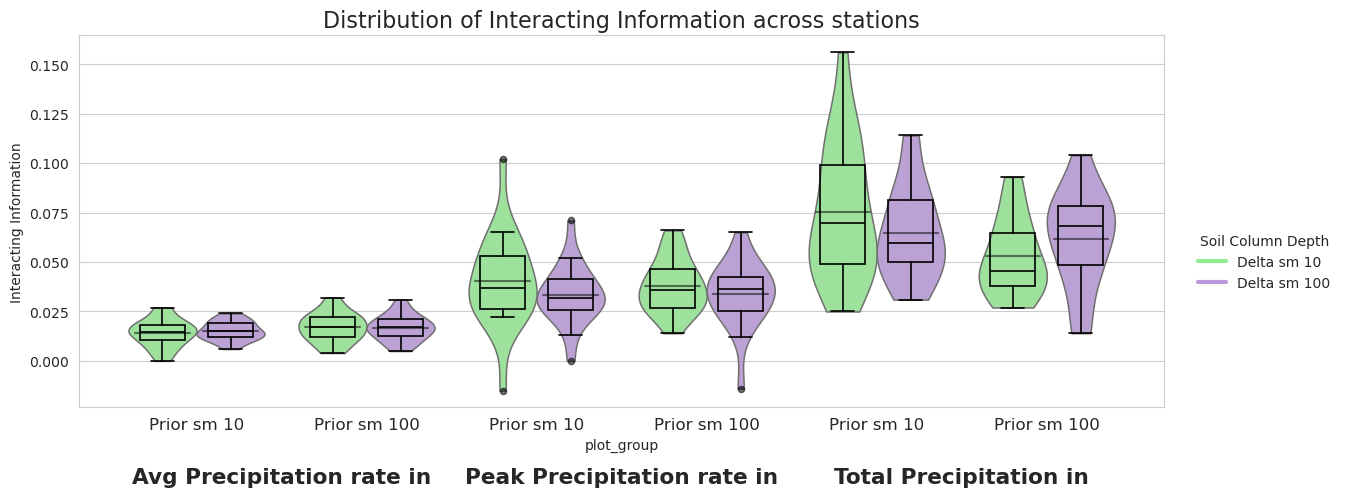

In [92]:
# Visualize station-level interacting information distributions for selected trivariate MI labels
tri_base_order = [
    "trivariate_MI_Avg_Precipitation_rate_in_Prior_sm_10",
    "trivariate_MI_Avg_Precipitation_rate_in_Prior_sm_100",
    "trivariate_MI_Peak_Precipitation_rate_in_Prior_sm_10",
    "trivariate_MI_Peak_Precipitation_rate_in_Prior_sm_100",
    "trivariate_MI_Total_Precipitation_in_Prior_sm_10",
    "trivariate_MI_Total_Precipitation_in_Prior_sm_100",
]

available_labels = set(
    trivar_MI.loc[
        (~trivar_MI["MI_label"].str.contains("Median_Precipitation_rate_in"))
        & (~trivar_MI["MI_label"].str.contains("_perPtot")),
        "MI_label",
    ]
)

def parse_components(label: str) -> tuple[str, str]:
    stripped = label.removeprefix("trivariate_MI_")
    if stripped.endswith("_Delta_sm_10"):
        stripped = stripped[: -len("_Delta_sm_10")]
    elif stripped.endswith("_Delta_sm_100"):
        stripped = stripped[: -len("_Delta_sm_100")]
    else:
        raise ValueError(f"Unexpected label format: {label}")
    first_part, prior_suffix = stripped.rsplit("_Prior_sm_", 1)
    first_var = first_part.replace("_", " ")
    prior_label = f"Prior sm {prior_suffix}"
    return first_var, prior_label

selected_label_pairs = []
for base in tri_base_order:
    label_10 = f"{base}_Delta_sm_10"
    label_100 = f"{base}_Delta_sm_100"
    if label_10 in available_labels and label_100 in available_labels:
        selected_label_pairs.append((label_10, label_100))

if not selected_label_pairs:
    raise ValueError("No trivariate MI labels matched the filtering criteria.")

group_meta: dict[str, tuple[str, str]] = {}
group_keys: list[str] = []
for label_10, label_100 in selected_label_pairs:
    first_var, prior_label = parse_components(label_10)
    key = f"{first_var}__{prior_label}"
    group_meta[key] = (first_var, prior_label)
    group_keys.append(key)

plot_df = (
    trivar_MI.loc[
        trivar_MI["MI_label"].isin([label for pair in selected_label_pairs for label in pair]),
        ["station", "MI_label", "Interacting_information"],
    ]
    .copy()
)

plot_df["delta_depth"] = plot_df["MI_label"].apply(
    lambda label: "Delta_sm_100" if "Delta_sm_100" in label else "Delta_sm_10"
)
plot_df["first_variable"] = plot_df["MI_label"].apply(lambda label: parse_components(label)[0])
plot_df["prior_label"] = plot_df["MI_label"].apply(lambda label: parse_components(label)[1])
plot_df["plot_group_key"] = plot_df["first_variable"] + "__" + plot_df["prior_label"]
plot_df["plot_group"] = pd.Categorical(
    plot_df["plot_group_key"], categories=group_keys, ordered=True
)
plot_df = plot_df[plot_df["plot_group"].notna()]
plot_df["plot_group"] = plot_df["plot_group"].cat.remove_unused_categories()
plot_df = plot_df.sort_values("plot_group")

if plot_df.empty:
    raise ValueError("No interacting information values remained after filtering.")

group_order = list(plot_df["plot_group"].cat.categories)

palette_map = {"Delta_sm_10": "#92ec92", "Delta_sm_100": "#bc98dd"}
hue_order = ["Delta_sm_10", "Delta_sm_100"]

sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(14, 6))
sns.violinplot(
    data=plot_df,
    x="plot_group",
    y="Interacting_information",
    order=group_order,
    hue="delta_depth",
    hue_order=hue_order,
    palette=palette_map,
    dodge=True,
    cut=0,
    inner=None,
    linewidth=1.1,
    width=0.8,
    density_norm="width",
    ax=ax,
)


violin_width = 0.8
n_levels = len(hue_order)
box_width = violin_width / (n_levels + 1)
line_half_width = box_width * 0.6
mean_lookup = (
    plot_df.groupby(["plot_group", "delta_depth"], observed=False)["Interacting_information"]
           .mean()
           .to_dict()
)

for x_idx, group in enumerate(group_order):
    for level_idx, level in enumerate(hue_order):
        subset = plot_df[(plot_df["plot_group"] == group) & (plot_df["delta_depth"] == level)]
        if subset.empty:
            continue
        offset = (-0.5 + (level_idx + 0.5) / n_levels) * violin_width
        center = x_idx + offset

        bp = ax.boxplot(
            subset["Interacting_information"],
            positions=[center],
            widths=box_width,
            patch_artist=True,
            manage_ticks=False,
            showcaps=True,
            boxprops={"facecolor": "none", "edgecolor": "black", "linewidth": 1.2},
            whiskerprops={"linewidth": 1.2, "color": "black"},
            capprops={"linewidth": 1.2, "color": "black"},
            medianprops={"linewidth": 1.2, "color": "black"},
            flierprops={"marker": "o", "markersize": 4.5, "markerfacecolor": "black", "markeredgecolor": "black", "alpha": 0.55},
        )
        for element in ['whiskers', 'caps']:
            for artist in bp[element]:
                artist.set(color='black', linewidth=1.2)

        mean_val = mean_lookup.get((group, level))
        if mean_val is not None:
            ax.plot([center - line_half_width, center + line_half_width], [mean_val, mean_val], color="black", linewidth=1.5, alpha=0.5)

if ax.legend_ is not None:
    ax.legend_.remove()
legend_handles = [
    plt.Line2D([0], [0], color=palette_map[key], lw=3, label=key.replace("_", " "))
    for key in hue_order
]
ax.legend(handles=legend_handles, title="Soil Column Depth", frameon=False, bbox_to_anchor = (1.02, 0.5))

from collections import Counter

base_counts = Counter(group_meta[key][0] for key in group_order)
tick_labels = [group_meta[key][1] for key in group_order]
ax.set_xticks(range(len(group_order)))
ax.set_xticklabels(tick_labels, rotation=0, ha="center", fontsize =12)

label_fontsize = ax.get_xticklabels()[0].get_fontsize() if ax.get_xticklabels() else plt.rcParams.get("font.size", 10)
for base, count in base_counts.items():
    positions = [idx for idx, key in enumerate(group_order) if group_meta[key][0] == base]
    if not positions:
        continue
    midpoint = sum(positions) / len(positions)
    ax.text(
        midpoint,
        -0.16,
        base,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=label_fontsize * 1.3,
        fontweight="bold",
    )

ax.set_ylabel("Interacting Information")
ax.set_title("Distribution of Interacting Information across stations", fontsize = 16)
fig.subplots_adjust(bottom=0.26)
plt.show()


Empty DataFrame
Columns: [station, MI_label, Interacting_information]
Index: []


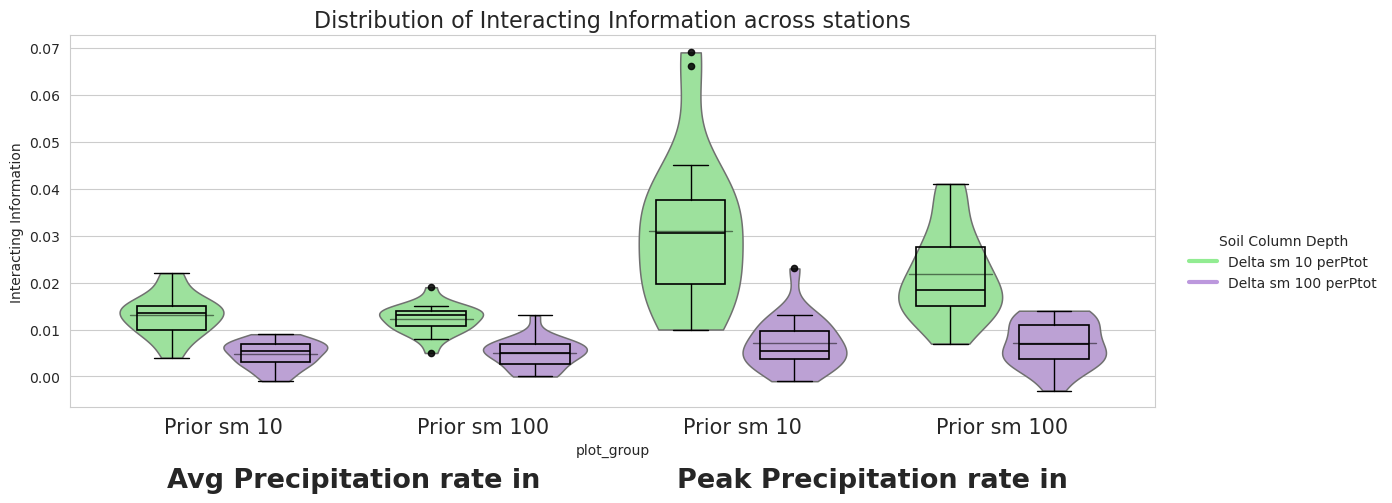

In [90]:
# Visualize station-level interacting information distributions for selected trivariate MI labels
tri_base_order = [
    "trivariate_MI_Avg_Precipitation_rate_in_Prior_sm_10",
    "trivariate_MI_Avg_Precipitation_rate_in_Prior_sm_100",
    "trivariate_MI_Peak_Precipitation_rate_in_Prior_sm_10",
    "trivariate_MI_Peak_Precipitation_rate_in_Prior_sm_100",
    "trivariate_MI_Total_Precipitation_in_Prior_sm_10",
    "trivariate_MI_Total_Precipitation_in_Prior_sm_100",
]

available_labels = set(
    trivar_MI.loc[
        (~trivar_MI["MI_label"].str.contains("Median_Precipitation_rate_in"))
        & (trivar_MI["MI_label"].str.contains("_perPtot")),
        "MI_label",
    ]
)

def parse_components(label: str) -> tuple[str, str]:
    stripped = label.removeprefix("trivariate_MI_")
    if stripped.endswith("_Delta_sm_10_perPtot"):
        stripped = stripped[: -len("_Delta_sm_10_perPtot")]
    elif stripped.endswith("_Delta_sm_100_perPtot"):
        stripped = stripped[: -len("_Delta_sm_100_perPtot")]
    else:
        raise ValueError(f"Unexpected label format: {label}")
    first_part, prior_suffix = stripped.rsplit("_Prior_sm_", 1)
    first_var = first_part.replace("_", " ")
    prior_label = f"Prior sm {prior_suffix}"
    return first_var, prior_label

selected_label_pairs = []
for base in tri_base_order:
    label_10 = f"{base}_Delta_sm_10_perPtot"
    label_100 = f"{base}_Delta_sm_100_perPtot"
    if label_10 in available_labels and label_100 in available_labels:
        selected_label_pairs.append((label_10, label_100))

if not selected_label_pairs:
    raise ValueError("No trivariate MI labels matched the filtering criteria.")

group_meta: dict[str, tuple[str, str]] = {}
group_keys: list[str] = []
for label_10, label_100 in selected_label_pairs:
    first_var, prior_label = parse_components(label_10)
    key = f"{first_var}__{prior_label}"
    group_meta[key] = (first_var, prior_label)
    group_keys.append(key)

plot_df = (
    trivar_MI.loc[
        trivar_MI["MI_label"].isin([label for pair in selected_label_pairs for label in pair]),
        ["station", "MI_label", "Interacting_information"],
    ]
    .copy()
)
print(plot_df.loc[plot_df['Interacting_information'] < -0.12])

plot_df["delta_depth"] = plot_df["MI_label"].apply(
    lambda label: "Delta_sm_100_perPtot" if "Delta_sm_100_perPtot" in label else "Delta_sm_10_perPtot"
)
plot_df["first_variable"] = plot_df["MI_label"].apply(lambda label: parse_components(label)[0])
plot_df["prior_label"] = plot_df["MI_label"].apply(lambda label: parse_components(label)[1])
plot_df["plot_group_key"] = plot_df["first_variable"] + "__" + plot_df["prior_label"]
plot_df["plot_group"] = pd.Categorical(
    plot_df["plot_group_key"], categories=group_keys, ordered=True
)
plot_df = plot_df[plot_df["plot_group"].notna()]
plot_df["plot_group"] = plot_df["plot_group"].cat.remove_unused_categories()
plot_df = plot_df.sort_values("plot_group")

if plot_df.empty:
    raise ValueError("No interacting information values remained after filtering.")

group_order = list(plot_df["plot_group"].cat.categories)

palette_map = {"Delta_sm_10_perPtot": "#92ec92", "Delta_sm_100_perPtot": "#bc98dd"}
hue_order = ["Delta_sm_10_perPtot", "Delta_sm_100_perPtot"]

sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(14, 6))
sns.violinplot(
    data=plot_df,
    x="plot_group",
    y="Interacting_information",
    order=group_order,
    hue="delta_depth",
    hue_order=hue_order,
    palette=palette_map,
    dodge=True,
    cut=0,
    inner=None,
    linewidth=1.1,
    width=0.8,
    density_norm="width",
    ax=ax,
)


violin_width = 0.8
n_levels = len(hue_order)
box_width = violin_width / (n_levels + 1)
line_half_width = box_width * 0.6
mean_lookup = (
    plot_df.groupby(["plot_group", "delta_depth"], observed=False)["Interacting_information"]
           .mean()
           .to_dict()
)

for x_idx, group in enumerate(group_order):
    for level_idx, level in enumerate(hue_order):
        subset = plot_df[(plot_df["plot_group"] == group) & (plot_df["delta_depth"] == level)]
        if subset.empty:
            continue
        offset = (-0.5 + (level_idx + 0.5) / n_levels) * violin_width
        center = x_idx + offset

        bp = ax.boxplot(
            subset["Interacting_information"],
            positions=[center],
            widths=box_width,
            patch_artist=True,
            manage_ticks=False,
            showcaps=True,
            boxprops={"facecolor": "none", "edgecolor": "black", "linewidth": 1.2},
            whiskerprops={"linewidth": 1.2, "color": "black"},
            capprops={"linewidth": 1.2, "color": "black"},
            medianprops={"linewidth": 1.2, "color": "black"},
            flierprops={"marker": "o", "markersize": 4.5, "markerfacecolor": "black", "markeredgecolor": "black", "alpha": 0.85},
        )
        for element in ['whiskers', 'caps']:
            for artist in bp[element]:
                artist.set(color='black', linewidth=1)

        mean_val = mean_lookup.get((group, level))
        if mean_val is not None:
            ax.plot([center - line_half_width, center + line_half_width], [mean_val, mean_val], color="black", linewidth=1, alpha=0.5)

if ax.legend_ is not None:
    ax.legend_.remove()
legend_handles = [
    plt.Line2D([0], [0], color=palette_map[key], lw=3, label=key.replace("_", " "))
    for key in hue_order
]
ax.legend(handles=legend_handles, title="Soil Column Depth", frameon=False, bbox_to_anchor = (1.02, 0.5))

from collections import Counter

base_counts = Counter(group_meta[key][0] for key in group_order)
tick_labels = [group_meta[key][1] for key in group_order]
ax.set_xticks(range(len(group_order)))
ax.set_xticklabels(tick_labels, rotation=0, ha="center", fontsize= 15)

label_fontsize = ax.get_xticklabels()[0].get_fontsize() if ax.get_xticklabels() else plt.rcParams.get("font.size", 10)
for base, count in base_counts.items():
    positions = [idx for idx, key in enumerate(group_order) if group_meta[key][0] == base]
    if not positions:
        continue
    midpoint = sum(positions) / len(positions)
    ax.text(
        midpoint,
        -0.16,
        base,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=label_fontsize * 1.3,
        fontweight="bold",
    )

ax.set_ylabel("Interacting Information")
ax.set_title("Distribution of Interacting Information across stations", fontsize = 16)
fig.subplots_adjust(bottom=0.26)
plt.show()


# plot violins for U,S,R for Peak, total P

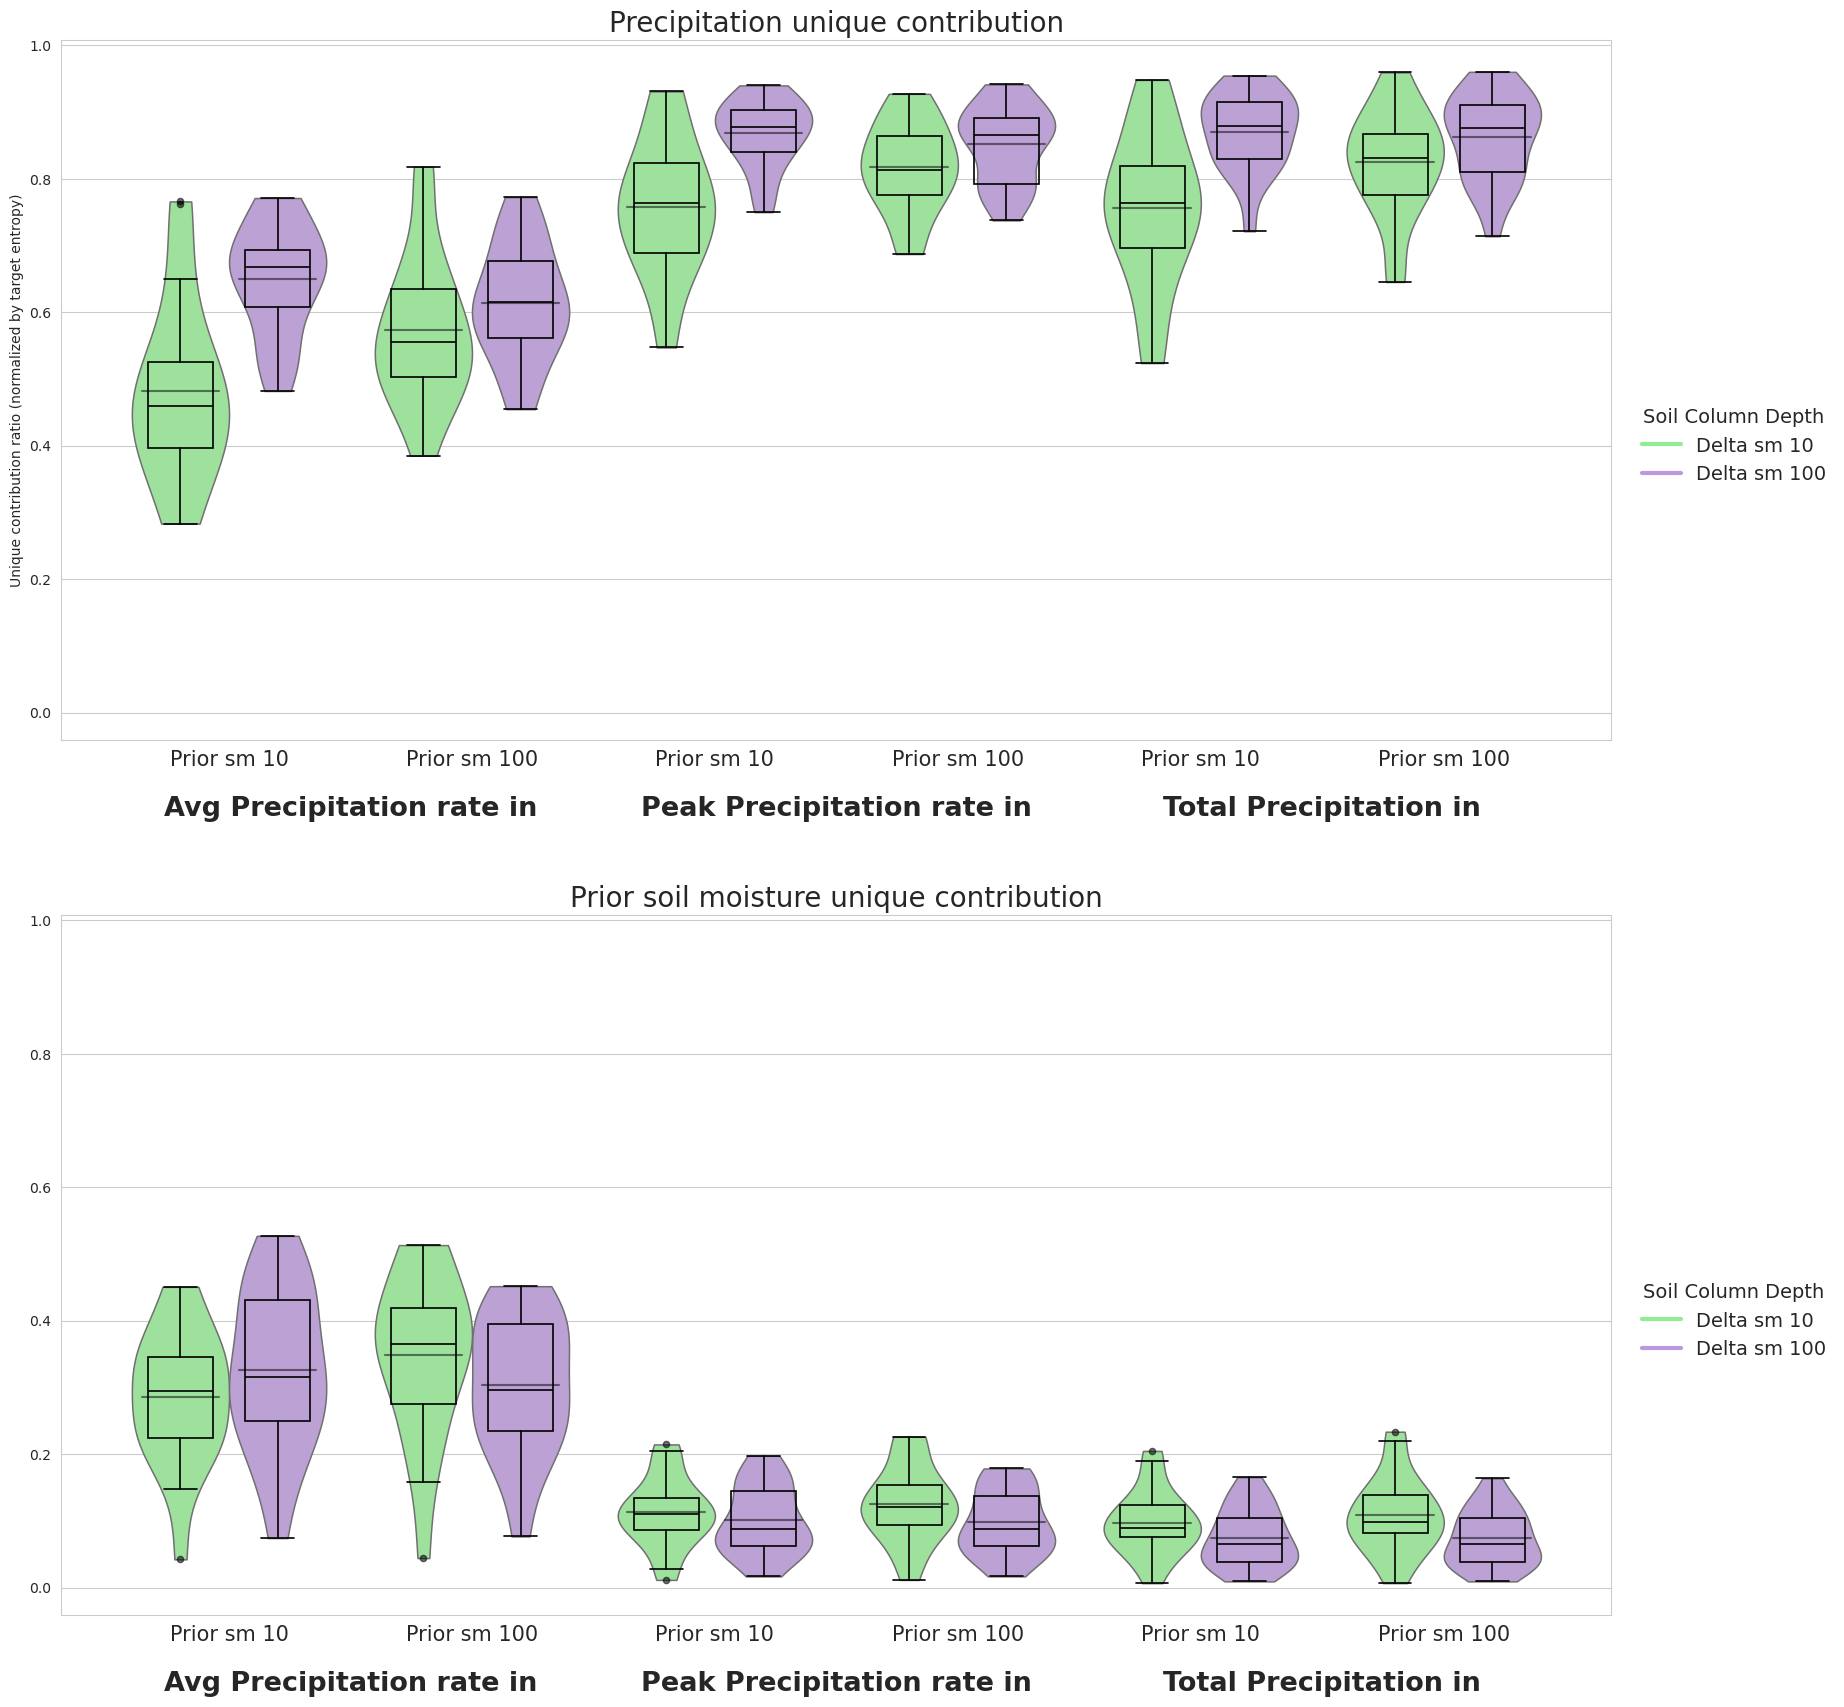

In [89]:
# Visualize unique contribution ratios for precipitation and prior soil moisture
unique_base_order = [
    "trivariate_MI_Avg_Precipitation_rate_in_Prior_sm_10",
    "trivariate_MI_Avg_Precipitation_rate_in_Prior_sm_100",
    "trivariate_MI_Peak_Precipitation_rate_in_Prior_sm_10",
    "trivariate_MI_Peak_Precipitation_rate_in_Prior_sm_100",
    "trivariate_MI_Total_Precipitation_in_Prior_sm_10",
    "trivariate_MI_Total_Precipitation_in_Prior_sm_100",
]
available_labels = set(
    Partition_values.loc[
        ~Partition_values["MI_label"].str.contains("Median_Precipitation_rate_in")
        & ~Partition_values["MI_label"].str.contains("_perPtot"),
        "MI_label",
    ]
)

def parse_tri_components(label: str) -> tuple[str, str]:
    stripped = label.removeprefix("trivariate_MI_")
    if stripped.endswith("_Delta_sm_10"):
        stripped = stripped[: -len("_Delta_sm_10")]
    elif stripped.endswith("_Delta_sm_100"):
        stripped = stripped[: -len("_Delta_sm_100")]
    else:
        raise ValueError(f"Unexpected label format: {label}")
    first_part, prior_suffix = stripped.rsplit("_Prior_sm_", 1)
    first_var = first_part.replace("_", " ")
    prior_label = f"Prior sm {prior_suffix}"
    return first_var, prior_label

selected_label_pairs = []
for base in unique_base_order:
    label_10 = f"{base}_Delta_sm_10"
    label_100 = f"{base}_Delta_sm_100"
    if label_10 in available_labels and label_100 in available_labels:
        selected_label_pairs.append((label_10, label_100))

if not selected_label_pairs:
    raise ValueError("No matching Partition_values labels found for requested combinations.")

group_meta: dict[str, tuple[str, str]] = {}
group_keys: list[str] = []
for label_10, label_100 in selected_label_pairs:
    first_var, prior_label = parse_tri_components(label_10)
    key = f"{first_var}__{prior_label}"
    group_meta[key] = (first_var, prior_label)
    group_keys.append(key)

plot_df = (
    Partition_values.loc[
        Partition_values["MI_label"].isin([label for pair in selected_label_pairs for label in pair]),
        ["Station", "MI_label", "Unique_xz_ratio", "Unique_yz_ratio"],
    ].copy()
)

plot_df["delta_depth"] = plot_df["MI_label"].apply(
    lambda label: "Delta_sm_100" if "Delta_sm_100" in label else "Delta_sm_10"
)
plot_df["first_variable"] = plot_df["MI_label"].apply(lambda label: parse_tri_components(label)[0])
plot_df["prior_label"] = plot_df["MI_label"].apply(lambda label: parse_tri_components(label)[1])
plot_df["plot_group_key"] = plot_df["first_variable"] + "__" + plot_df["prior_label"]
plot_df["plot_group"] = pd.Categorical(plot_df["plot_group_key"], categories=group_keys, ordered=True)
plot_df = plot_df[plot_df["plot_group"].notna()].copy()
plot_df["plot_group"] = plot_df["plot_group"].cat.remove_unused_categories()
plot_df = plot_df.sort_values("plot_group")

if plot_df.empty:
    raise ValueError("No Partition_values remained after filtering for unique ratio visualization.")

group_order = list(plot_df["plot_group"].cat.categories)

unique_long = plot_df.melt(
    id_vars=["Station", "MI_label", "delta_depth", "first_variable", "prior_label", "plot_group_key", "plot_group"],
    value_vars=["Unique_xz_ratio", "Unique_yz_ratio"],
    var_name="unique_component",
    value_name="unique_ratio",
)

unique_label_map = {
    "Unique_xz_ratio": "Precipitation unique contribution",
    "Unique_yz_ratio": "Prior soil moisture unique contribution",
}
unique_order = [unique_label_map["Unique_xz_ratio"], unique_label_map["Unique_yz_ratio"]]
unique_long["unique_label"] = unique_long["unique_component"].map(unique_label_map)
unique_long = unique_long.dropna(subset=["unique_ratio"])
unique_long["unique_label"] = pd.Categorical(unique_long["unique_label"], categories=unique_order, ordered=True)
unique_long["plot_group"] = pd.Categorical(unique_long["plot_group"], categories=group_order, ordered=True)
unique_long = unique_long.sort_values(["unique_label", "plot_group"])

palette_map = {"Delta_sm_10": "#92ec92", "Delta_sm_100": "#bc98dd"}
hue_order = ["Delta_sm_10", "Delta_sm_100"]

sns.set_style("whitegrid")
fig, axes = plt.subplots(len(unique_order), 1, figsize=(20, 25), sharey=True)
axes = np.atleast_1d(axes)

violin_width = 0.8
n_levels = len(hue_order)
box_width = violin_width / (n_levels + 1)
line_half_width = box_width * 0.6

from collections import Counter

base_counts = Counter(group_meta[key][0] for key in group_order)
tick_labels = [group_meta[key][1] for key in group_order]

for ax, unique_label in zip(axes, unique_order):
    subset = unique_long[unique_long["unique_label"] == unique_label]
    if subset.empty:
        ax.set_visible(False)
        continue

    sns.violinplot(
        data=subset,
        x="plot_group",
        y="unique_ratio",
        order=group_order,
        hue="delta_depth",
        hue_order=hue_order,
        palette=palette_map,
        dodge=True,
        cut=0,
        inner=None,
        linewidth=1.1,
        width=violin_width,
        density_norm="width",
        ax=ax,
    )

    mean_lookup = (
        subset.groupby(["plot_group", "delta_depth"], observed=False)["unique_ratio"]
               .mean()
               .to_dict()
    )

    for x_idx, group in enumerate(group_order):
        for level_idx, level in enumerate(hue_order):
            group_subset = subset[(subset["plot_group"] == group) & (subset["delta_depth"] == level)]
            if group_subset.empty:
                continue

            offset = (-0.5 + (level_idx + 0.5) / n_levels) * violin_width
            center = x_idx + offset

            bp = ax.boxplot(
                group_subset["unique_ratio"],
                positions=[center],
                widths=box_width,
                patch_artist=True,
                manage_ticks=False,
                showcaps=True,
                boxprops={"facecolor": "none", "edgecolor": "black", "linewidth": 1.2},
                whiskerprops={"linewidth": 1.2, "color": "black"},
                capprops={"linewidth": 1.2, "color": "black"},
                medianprops={"linewidth": 1.2, "color": "black"},
                flierprops={"marker": "o", "markersize": 4.5, "markerfacecolor": "black", "markeredgecolor": "black", "alpha": 0.55},
            )
            for element in ["whiskers", "caps"]:
                for artist in bp[element]:
                    artist.set(color="black", linewidth=1.2)

            mean_val = mean_lookup.get((group, level))
            if mean_val is not None:
                ax.plot(
                    [center - line_half_width, center + line_half_width],
                    [mean_val, mean_val],
                    color="black",
                    linewidth=1.5,
                    alpha=0.5,
                )

    if ax.legend_ is not None:
        ax.legend_.remove()

    ax.set_xticks(range(len(group_order)))
    ax.set_xticklabels(tick_labels, rotation=0, ha="center", fontsize= 15)
    label_fontsize = ax.get_xticklabels()[0].get_fontsize() if ax.get_xticklabels() else plt.rcParams.get("font.size", 10)

    for base, count in base_counts.items():
        positions = [idx for idx, key in enumerate(group_order) if group_meta[key][0] == base]
        if not positions:
            continue
        midpoint = sum(positions) / len(positions)
        ax.text(
            midpoint,
            -0.08,
            base,
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="top",
            fontsize=label_fontsize * 1.3,
            fontweight="bold",
        )

    ax.set_title(unique_label, fontsize=20)
    ax.set_xlabel("")

axes[0].set_ylabel("Unique contribution ratio (normalized by target entropy)")
axes[1].set_ylabel("Unique contribution ratio (normalized by target entropy)")
legend_handles = [
    plt.Line2D([0], [0], color=palette_map[key], lw=3, label=key.replace("_", " "))
    for key in hue_order
]
axes[0].legend(handles=legend_handles, title="Soil Column Depth", title_fontsize =14, fontsize =14, frameon=False, bbox_to_anchor = (1.15, 0.5))
axes[1].legend(handles=legend_handles, title="Soil Column Depth", title_fontsize =14, fontsize =14, frameon=False, bbox_to_anchor = (1.15, 0.5))

for ax in axes[1:]:
    ax.set_ylabel("")

fig.subplots_adjust(bottom=0.25, hspace=0.25)
plt.show()


    Station                                           MI_label  \
437     sfm  trivariate_MI_Peak_Precipitation_rate_in_Prior...   
440     sfm  trivariate_MI_Peak_Precipitation_rate_in_Prior...   

     Redundancy_zratio  Synergistic_ratio  
437           0.015601           0.001183  
440           0.017622           0.000768  


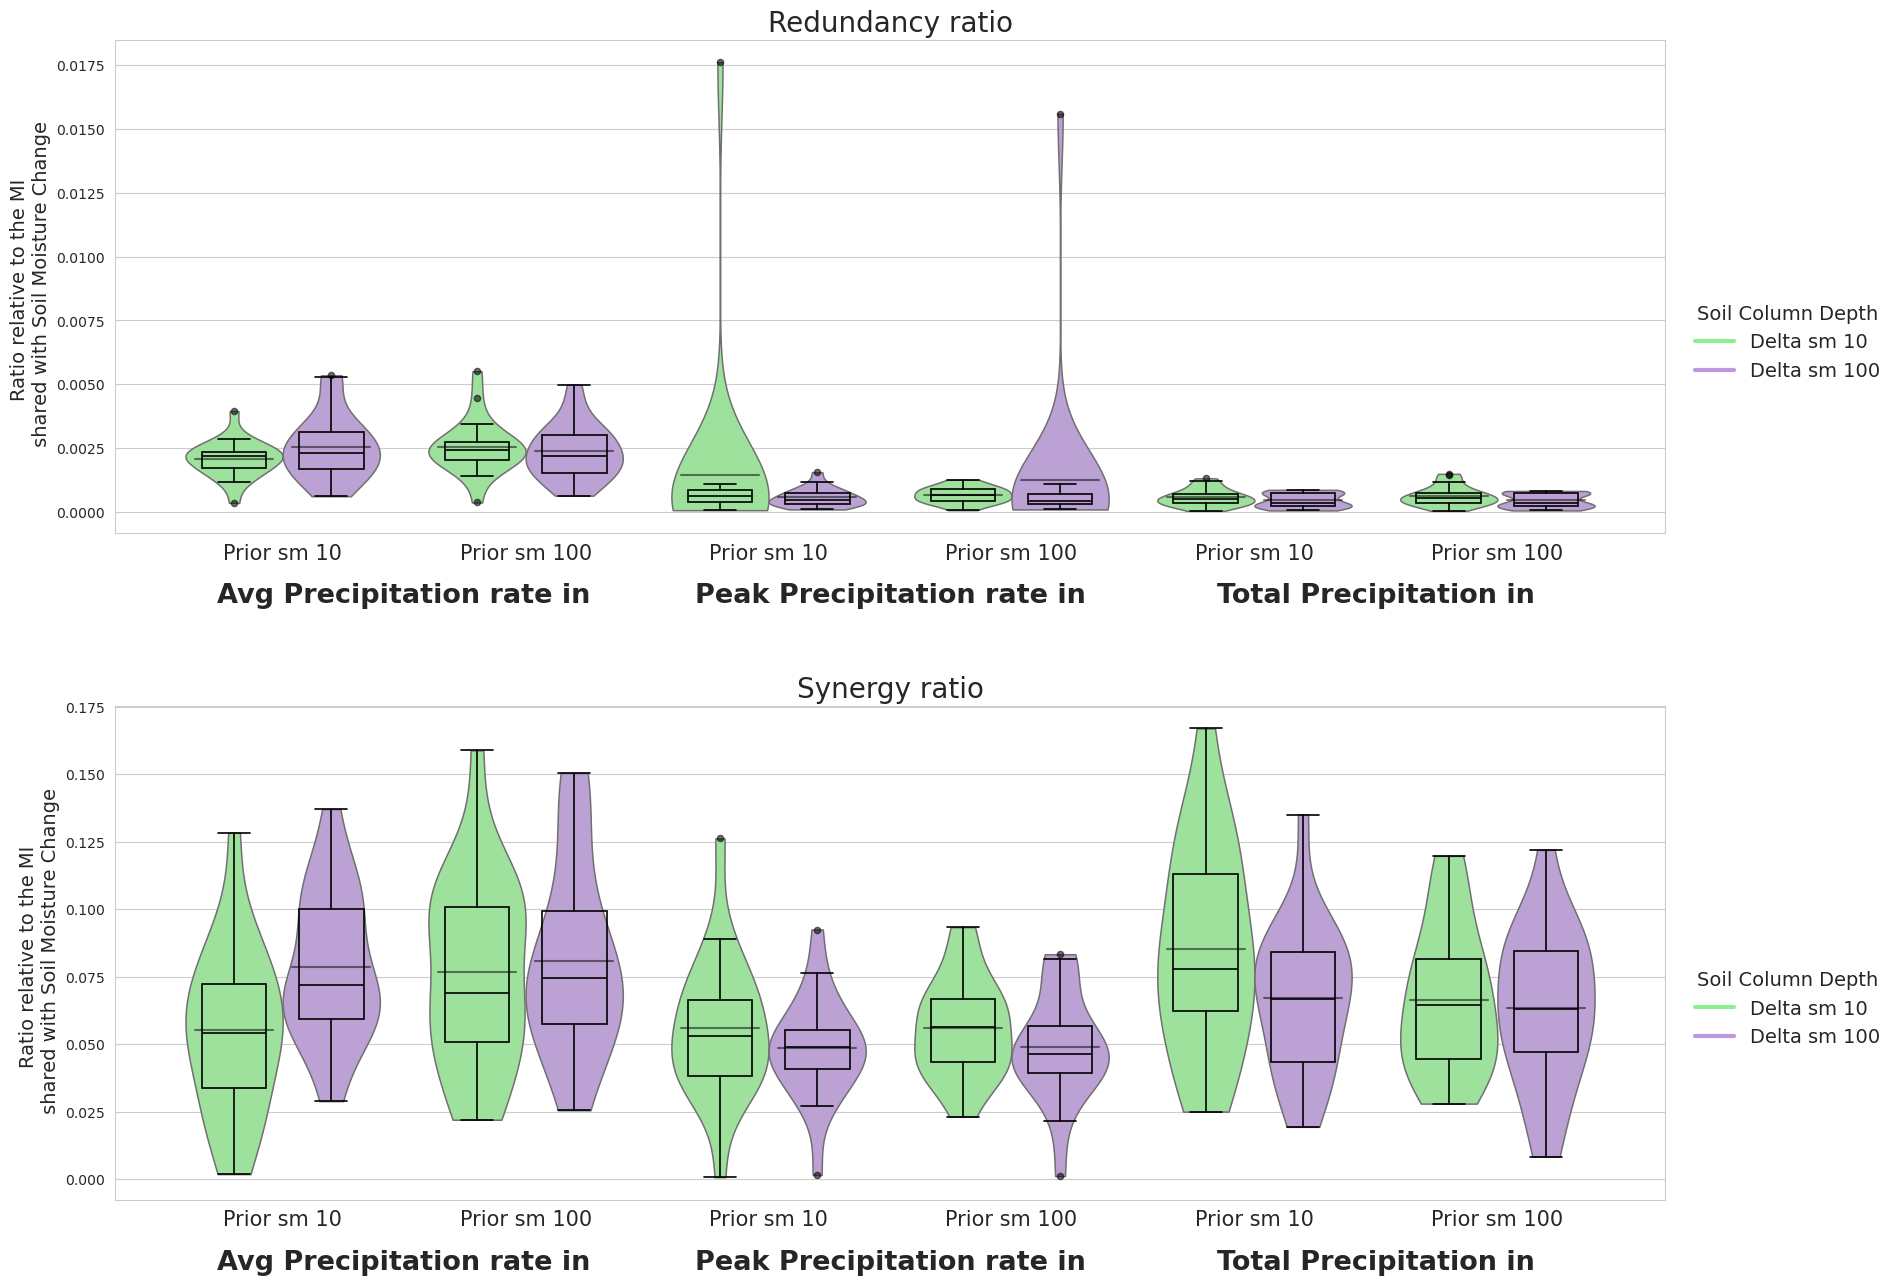

In [87]:
# Visualize redundancy and synergy ratios for precipitation and prior soil moisture
redundancy_base_order = [
    "trivariate_MI_Avg_Precipitation_rate_in_Prior_sm_10",
    "trivariate_MI_Avg_Precipitation_rate_in_Prior_sm_100",
    "trivariate_MI_Peak_Precipitation_rate_in_Prior_sm_10",
    "trivariate_MI_Peak_Precipitation_rate_in_Prior_sm_100",
    "trivariate_MI_Total_Precipitation_in_Prior_sm_10",
    "trivariate_MI_Total_Precipitation_in_Prior_sm_100",
]
available_labels = set(
    Partition_values.loc[
        ~Partition_values["MI_label"].str.contains("Median_Precipitation_rate_in")
        & ~Partition_values["MI_label"].str.contains("_perPtot"),
        "MI_label",
    ]
)

def parse_tri_components(label: str) -> tuple[str, str]:  # reuse helper for clarity
    stripped = label.removeprefix("trivariate_MI_")
    if stripped.endswith("_Delta_sm_10"):
        stripped = stripped[: -len("_Delta_sm_10")]
    elif stripped.endswith("_Delta_sm_100"):
        stripped = stripped[: -len("_Delta_sm_100")]
    else:
        raise ValueError(f"Unexpected label format: {label}")
    first_part, prior_suffix = stripped.rsplit("_Prior_sm_", 1)
    first_var = first_part.replace("_", " ")
    prior_label = f"Prior sm {prior_suffix}"
    return first_var, prior_label

selected_label_pairs = []
for base in redundancy_base_order:
    label_10 = f"{base}_Delta_sm_10"
    label_100 = f"{base}_Delta_sm_100"
    if label_10 in available_labels and label_100 in available_labels:
        selected_label_pairs.append((label_10, label_100))

if not selected_label_pairs:
    raise ValueError("No matching Partition_values labels found for redundancy/synergy visualization.")

group_meta: dict[str, tuple[str, str]] = {}
group_keys: list[str] = []
for label_10, label_100 in selected_label_pairs:
    first_var, prior_label = parse_tri_components(label_10)
    key = f"{first_var}__{prior_label}"
    group_meta[key] = (first_var, prior_label)
    group_keys.append(key)

metrics = ["Redundancy_zratio", "Synergistic_ratio"]
plot_df = (
    Partition_values.loc[
        Partition_values["MI_label"].isin([label for pair in selected_label_pairs for label in pair]),
        ["Station", "MI_label", *metrics],
    ].copy()
)
print(plot_df.loc[plot_df['Redundancy_zratio'] > 0.0125])

plot_df["delta_depth"] = plot_df["MI_label"].apply(
    lambda label: "Delta_sm_100" if "Delta_sm_100" in label else "Delta_sm_10"
)
plot_df["first_variable"] = plot_df["MI_label"].apply(lambda label: parse_tri_components(label)[0])
plot_df["prior_label"] = plot_df["MI_label"].apply(lambda label: parse_tri_components(label)[1])
plot_df["plot_group_key"] = plot_df["first_variable"] + "__" + plot_df["prior_label"]
plot_df["plot_group"] = pd.Categorical(plot_df["plot_group_key"], categories=group_keys, ordered=True)
plot_df = plot_df[plot_df["plot_group"].notna()].copy()
plot_df["plot_group"] = plot_df["plot_group"].cat.remove_unused_categories()
plot_df = plot_df.sort_values("plot_group")

if plot_df.empty:
    raise ValueError("No Partition_values remained after filtering for redundancy/synergy visualization.")

group_order = list(plot_df["plot_group"].cat.categories)

metric_long = plot_df.melt(
    id_vars=["Station", "MI_label", "delta_depth", "first_variable", "prior_label", "plot_group_key", "plot_group"],
    value_vars=metrics,
    var_name="metric_name",
    value_name="ratio_value",
)

metric_label_map = {
    "Redundancy_zratio": "Redundancy ratio",
    "Synergistic_ratio": "Synergy ratio",
}
metric_order = [metric_label_map[name] for name in metrics]
metric_long["metric_label"] = metric_long["metric_name"].map(metric_label_map)
metric_long = metric_long.dropna(subset=["ratio_value"])
metric_long["metric_label"] = pd.Categorical(metric_long["metric_label"], categories=metric_order, ordered=True)
metric_long["plot_group"] = pd.Categorical(metric_long["plot_group"], categories=group_order, ordered=True)
metric_long = metric_long.sort_values(["metric_label", "plot_group"])

palette_map = {"Delta_sm_10": "#92ec92", "Delta_sm_100": "#bc98dd"}
hue_order = ["Delta_sm_10", "Delta_sm_100"]

sns.set_style("whitegrid")
fig, axes = plt.subplots(len(metric_order), 1, figsize=(20,20))
axes = np.atleast_1d(axes)

violin_width = 0.8
n_levels = len(hue_order)
box_width = violin_width / (n_levels + 1)
line_half_width = box_width * 0.6

from collections import Counter

base_counts = Counter(group_meta[key][0] for key in group_order)
tick_labels = [group_meta[key][1] for key in group_order]

for ax, metric_label in zip(axes, metric_order):
    subset = metric_long[metric_long["metric_label"] == metric_label]
    if subset.empty:
        ax.set_visible(False)
        continue

    sns.violinplot(
        data=subset,
        x="plot_group",
        y="ratio_value",
        order=group_order,
        hue="delta_depth",
        hue_order=hue_order,
        palette=palette_map,
        dodge=True,
        cut=0,
        inner=None,
        linewidth=1.1,
        width=violin_width,
        density_norm="width",
        ax=ax,
    )

    mean_lookup = (
        subset.groupby(["plot_group", "delta_depth"], observed=False)["ratio_value"]
               .mean()
               .to_dict()
    )

    for x_idx, group in enumerate(group_order):
        for level_idx, level in enumerate(hue_order):
            group_subset = subset[(subset["plot_group"] == group) & (subset["delta_depth"] == level)]
            if group_subset.empty:
                continue

            offset = (-0.5 + (level_idx + 0.5) / n_levels) * violin_width
            center = x_idx + offset

            bp = ax.boxplot(
                group_subset["ratio_value"],
                positions=[center],
                widths=box_width,
                patch_artist=True,
                manage_ticks=False,
                showcaps=True,
                boxprops={"facecolor": "none", "edgecolor": "black", "linewidth": 1.2},
                whiskerprops={"linewidth": 1.2, "color": "black"},
                capprops={"linewidth": 1.2, "color": "black"},
                medianprops={"linewidth": 1.2, "color": "black"},
                flierprops={"marker": "o", "markersize": 4.5, "markerfacecolor": "black", "markeredgecolor": "black", "alpha": 0.55},
            )
            for element in ["whiskers", "caps"]:
                for artist in bp[element]:
                    artist.set(color="black", linewidth=1.2)

            mean_val = mean_lookup.get((group, level))
            if mean_val is not None:
                ax.plot(
                    [center - line_half_width, center + line_half_width],
                    [mean_val, mean_val],
                    color="black",
                    linewidth=1.5,
                    alpha=0.5,
                )

    if ax.legend_ is not None:
        ax.legend_.remove()

    ax.set_xticks(range(len(group_order)))
    ax.set_xticklabels(tick_labels, rotation=0, ha="center", fontsize= 15)
    label_fontsize = ax.get_xticklabels()[0].get_fontsize() if ax.get_xticklabels() else plt.rcParams.get("font.size", 10)

    for base, count in base_counts.items():
        positions = [idx for idx, key in enumerate(group_order) if group_meta[key][0] == base]
        if not positions:
            continue
        midpoint = sum(positions) / len(positions)
        ax.text(
            midpoint,
            -0.10,
            base,
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="top",
            fontsize=label_fontsize * 1.3,
            fontweight="bold",
        )

    ax.set_title(metric_label, fontsize=20)
    ax.set_xlabel("")

axes[0].set_ylabel("Ratio relative to the MI \n shared with Soil Moisture Change", fontsize = 14)
axes[1].set_ylabel("Ratio relative to the MI \n shared with Soil Moisture Change", fontsize = 14)

legend_handles = [
    plt.Line2D([0], [0], color=palette_map[key], lw=3, label=key.replace("_", " "))
    for key in hue_order
]

axes[0].legend(handles=legend_handles, title="Soil Column Depth", title_fontsize =14, fontsize =14, frameon=False, bbox_to_anchor = (1.15, 0.5))
axes[1].legend(handles=legend_handles, title="Soil Column Depth", title_fontsize =14, fontsize =14, frameon=False, bbox_to_anchor = (1.15, 0.5))
fig.subplots_adjust(bottom=0.3, hspace=0.35)
plt.show()


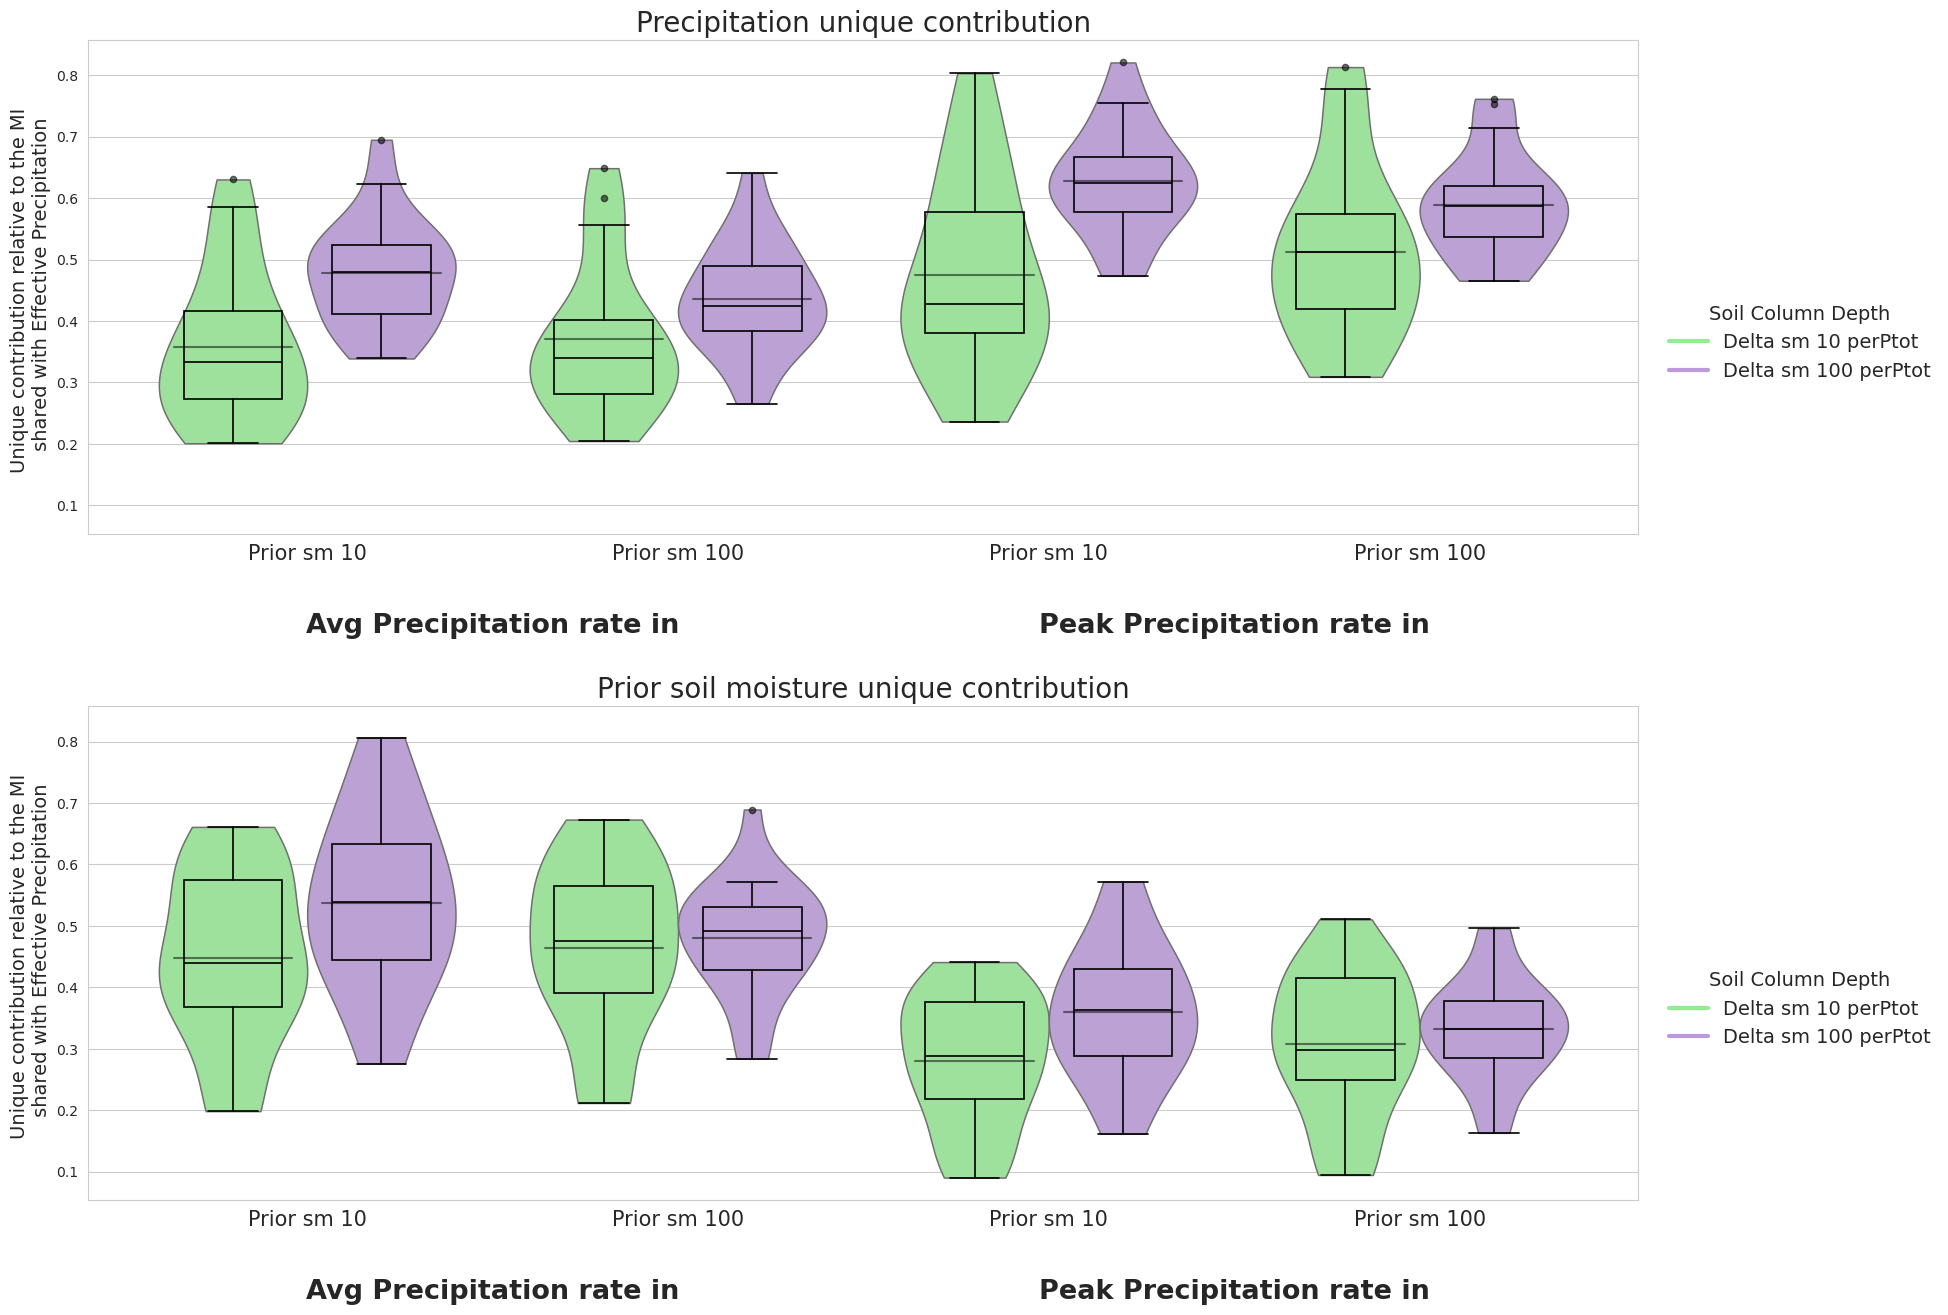

In [86]:
# Visualize unique contribution ratios (perPtot normalized targets) for precipitation and prior soil moisture
unique_perptot_base_order = [
    "trivariate_MI_Avg_Precipitation_rate_in_Prior_sm_10",
    "trivariate_MI_Avg_Precipitation_rate_in_Prior_sm_100",
    "trivariate_MI_Peak_Precipitation_rate_in_Prior_sm_10",
    "trivariate_MI_Peak_Precipitation_rate_in_Prior_sm_100",
]
available_perptot_labels = set(
    Partition_values.loc[
        ~Partition_values["MI_label"].str.contains("Median_Precipitation_rate_in")
        & Partition_values["MI_label"].str.contains("_perPtot"),
        "MI_label",
    ]
)

def parse_perptot_components(label: str) -> tuple[str, str]:
    stripped = label.removeprefix("trivariate_MI_")
    if stripped.endswith("_Delta_sm_10_perPtot"):
        stripped = stripped[: -len("_Delta_sm_10_perPtot")]
    elif stripped.endswith("_Delta_sm_100_perPtot"):
        stripped = stripped[: -len("_Delta_sm_100_perPtot")]
    else:
        raise ValueError(f"Unexpected perPtot label format: {label}")
    first_part, prior_suffix = stripped.rsplit("_Prior_sm_", 1)
    first_var = first_part.replace("_", " ")
    prior_label = f"Prior sm {prior_suffix}"
    return first_var, prior_label

selected_perptot_pairs = []
for base in unique_perptot_base_order:
    label_10 = f"{base}_Delta_sm_10_perPtot"
    label_100 = f"{base}_Delta_sm_100_perPtot"
    if label_10 in available_perptot_labels and label_100 in available_perptot_labels:
        selected_perptot_pairs.append((label_10, label_100))

if not selected_perptot_pairs:
    raise ValueError("No perPtot Partition_values labels found for requested unique ratio visualization.")

group_meta: dict[str, tuple[str, str]] = {}
group_keys: list[str] = []
for label_10, label_100 in selected_perptot_pairs:
    first_var, prior_label = parse_perptot_components(label_10)
    key = f"{first_var}__{prior_label}"
    group_meta[key] = (first_var, prior_label)
    group_keys.append(key)

perptot_plot_df = (
    Partition_values.loc[
        Partition_values["MI_label"].isin([label for pair in selected_perptot_pairs for label in pair]),
        ["Station", "MI_label", "Unique_xz_ratio", "Unique_yz_ratio"],
    ].copy()
)

perptot_plot_df["delta_depth"] = perptot_plot_df["MI_label"].apply(
    lambda label: "Delta_sm_100_perPtot" if "Delta_sm_100_perPtot" in label else "Delta_sm_10_perPtot"
)
perptot_plot_df["first_variable"] = perptot_plot_df["MI_label"].apply(lambda label: parse_perptot_components(label)[0])
perptot_plot_df["prior_label"] = perptot_plot_df["MI_label"].apply(lambda label: parse_perptot_components(label)[1])
perptot_plot_df["plot_group_key"] = perptot_plot_df["first_variable"] + "__" + perptot_plot_df["prior_label"]
perptot_plot_df["plot_group"] = pd.Categorical(perptot_plot_df["plot_group_key"], categories=group_keys, ordered=True)
perptot_plot_df = perptot_plot_df[perptot_plot_df["plot_group"].notna()].copy()
perptot_plot_df["plot_group"] = perptot_plot_df["plot_group"].cat.remove_unused_categories()
perptot_plot_df = perptot_plot_df.sort_values("plot_group")

if perptot_plot_df.empty:
    raise ValueError("No perPtot Partition_values remained after filtering for unique ratio visualization.")

group_order = list(perptot_plot_df["plot_group"].cat.categories)

unique_perptot_long = perptot_plot_df.melt(
    id_vars=["Station", "MI_label", "delta_depth", "first_variable", "prior_label", "plot_group_key", "plot_group"],
    value_vars=["Unique_xz_ratio", "Unique_yz_ratio"],
    var_name="unique_component",
    value_name="unique_ratio",
)

unique_label_map = {
    "Unique_xz_ratio": "Precipitation unique contribution",
    "Unique_yz_ratio": "Prior soil moisture unique contribution",
}
unique_order = [unique_label_map["Unique_xz_ratio"], unique_label_map["Unique_yz_ratio"]]
unique_perptot_long["unique_label"] = unique_perptot_long["unique_component"].map(unique_label_map)
unique_perptot_long = unique_perptot_long.dropna(subset=["unique_ratio"])
unique_perptot_long["unique_label"] = pd.Categorical(unique_perptot_long["unique_label"], categories=unique_order, ordered=True)
unique_perptot_long["plot_group"] = pd.Categorical(unique_perptot_long["plot_group"], categories=group_order, ordered=True)
unique_perptot_long = unique_perptot_long.sort_values(["unique_label", "plot_group"])

palette_map = {
    "Delta_sm_10_perPtot": "#92ec92",
    "Delta_sm_100_perPtot": "#bc98dd",
}
hue_order = ["Delta_sm_10_perPtot", "Delta_sm_100_perPtot"]

sns.set_style("whitegrid")
fig, axes = plt.subplots(len(unique_order), 1, figsize=(20,20), sharey=True)
axes = np.atleast_1d(axes)

violin_width = 0.8
n_levels = len(hue_order)
box_width = violin_width / (n_levels + 1)
line_half_width = box_width * 0.6

from collections import Counter

base_counts = Counter(group_meta[key][0] for key in group_order)
tick_labels = [group_meta[key][1] for key in group_order]

for ax, unique_label in zip(axes, unique_order):
    subset = unique_perptot_long[unique_perptot_long["unique_label"] == unique_label]
    if subset.empty:
        ax.set_visible(False)
        continue

    sns.violinplot(
        data=subset,
        x="plot_group",
        y="unique_ratio",
        order=group_order,
        hue="delta_depth",
        hue_order=hue_order,
        palette=palette_map,
        dodge=True,
        cut=0,
        inner=None,
        linewidth=1.1,
        width=violin_width,
        density_norm="width",
        ax=ax,
    )

    mean_lookup = (
        subset.groupby(["plot_group", "delta_depth"], observed=False)["unique_ratio"]
               .mean()
               .to_dict()
    )

    for x_idx, group in enumerate(group_order):
        for level_idx, level in enumerate(hue_order):
            group_subset = subset[(subset["plot_group"] == group) & (subset["delta_depth"] == level)]
            if group_subset.empty:
                continue

            offset = (-0.5 + (level_idx + 0.5) / n_levels) * violin_width
            center = x_idx + offset

            bp = ax.boxplot(
                group_subset["unique_ratio"],
                positions=[center],
                widths=box_width,
                patch_artist=True,
                manage_ticks=False,
                showcaps=True,
                boxprops={"facecolor": "none", "edgecolor": "black", "linewidth": 1.2},
                whiskerprops={"linewidth": 1.2, "color": "black"},
                capprops={"linewidth": 1.2, "color": "black"},
                medianprops={"linewidth": 1.2, "color": "black"},
                flierprops={"marker": "o", "markersize": 4.5, "markerfacecolor": "black", "markeredgecolor": "black", "alpha": 0.55},
            )
            for element in ["whiskers", "caps"]:
                for artist in bp[element]:
                    artist.set(color="black", linewidth=1.2)

            mean_val = mean_lookup.get((group, level))
            if mean_val is not None:
                ax.plot(
                    [center - line_half_width, center + line_half_width],
                    [mean_val, mean_val],
                    color="black",
                    linewidth=1.5,
                    alpha=0.5,
                )

    if ax.legend_ is not None:
        ax.legend_.remove()

    ax.set_xticks(range(len(group_order)))
    ax.set_xticklabels(tick_labels, rotation=0, ha="center", fontsize= 15)
    label_fontsize = ax.get_xticklabels()[0].get_fontsize() if ax.get_xticklabels() else plt.rcParams.get("font.size", 10)

    for base, count in base_counts.items():
        positions = [idx for idx, key in enumerate(group_order) if group_meta[key][0] == base]
        if not positions:
            continue
        midpoint = sum(positions) / len(positions)
        ax.text(
            midpoint,
            -0.16,
            base,
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="top",
            fontsize=label_fontsize * 1.3,
            fontweight="bold",
        )

    ax.set_title(unique_label, fontsize=20)
    ax.set_xlabel("")

axes[0].set_ylabel("Unique contribution relative to the MI \n shared with Effective Precipitation", fontsize =14)
axes[1].set_ylabel("Unique contribution relative to the MI \n shared with Effective Precipitation", fontsize =14)


legend_handles = [
    plt.Line2D([0], [0], color=palette_map[key], lw=3, label=key.replace("_", " "))
    for key in hue_order
]
axes[0].legend(handles=legend_handles, title="Soil Column Depth", frameon=False, loc="upper right")

axes[0].legend(handles=legend_handles, title="Soil Column Depth", title_fontsize =14, fontsize =14, frameon=False, bbox_to_anchor = (1.2, 0.5))
axes[1].legend(handles=legend_handles, title="Soil Column Depth", title_fontsize =14, fontsize =14, frameon=False, bbox_to_anchor = (1.2, 0.5))
fig.subplots_adjust(bottom=0.3, hspace=0.35)
plt.show()


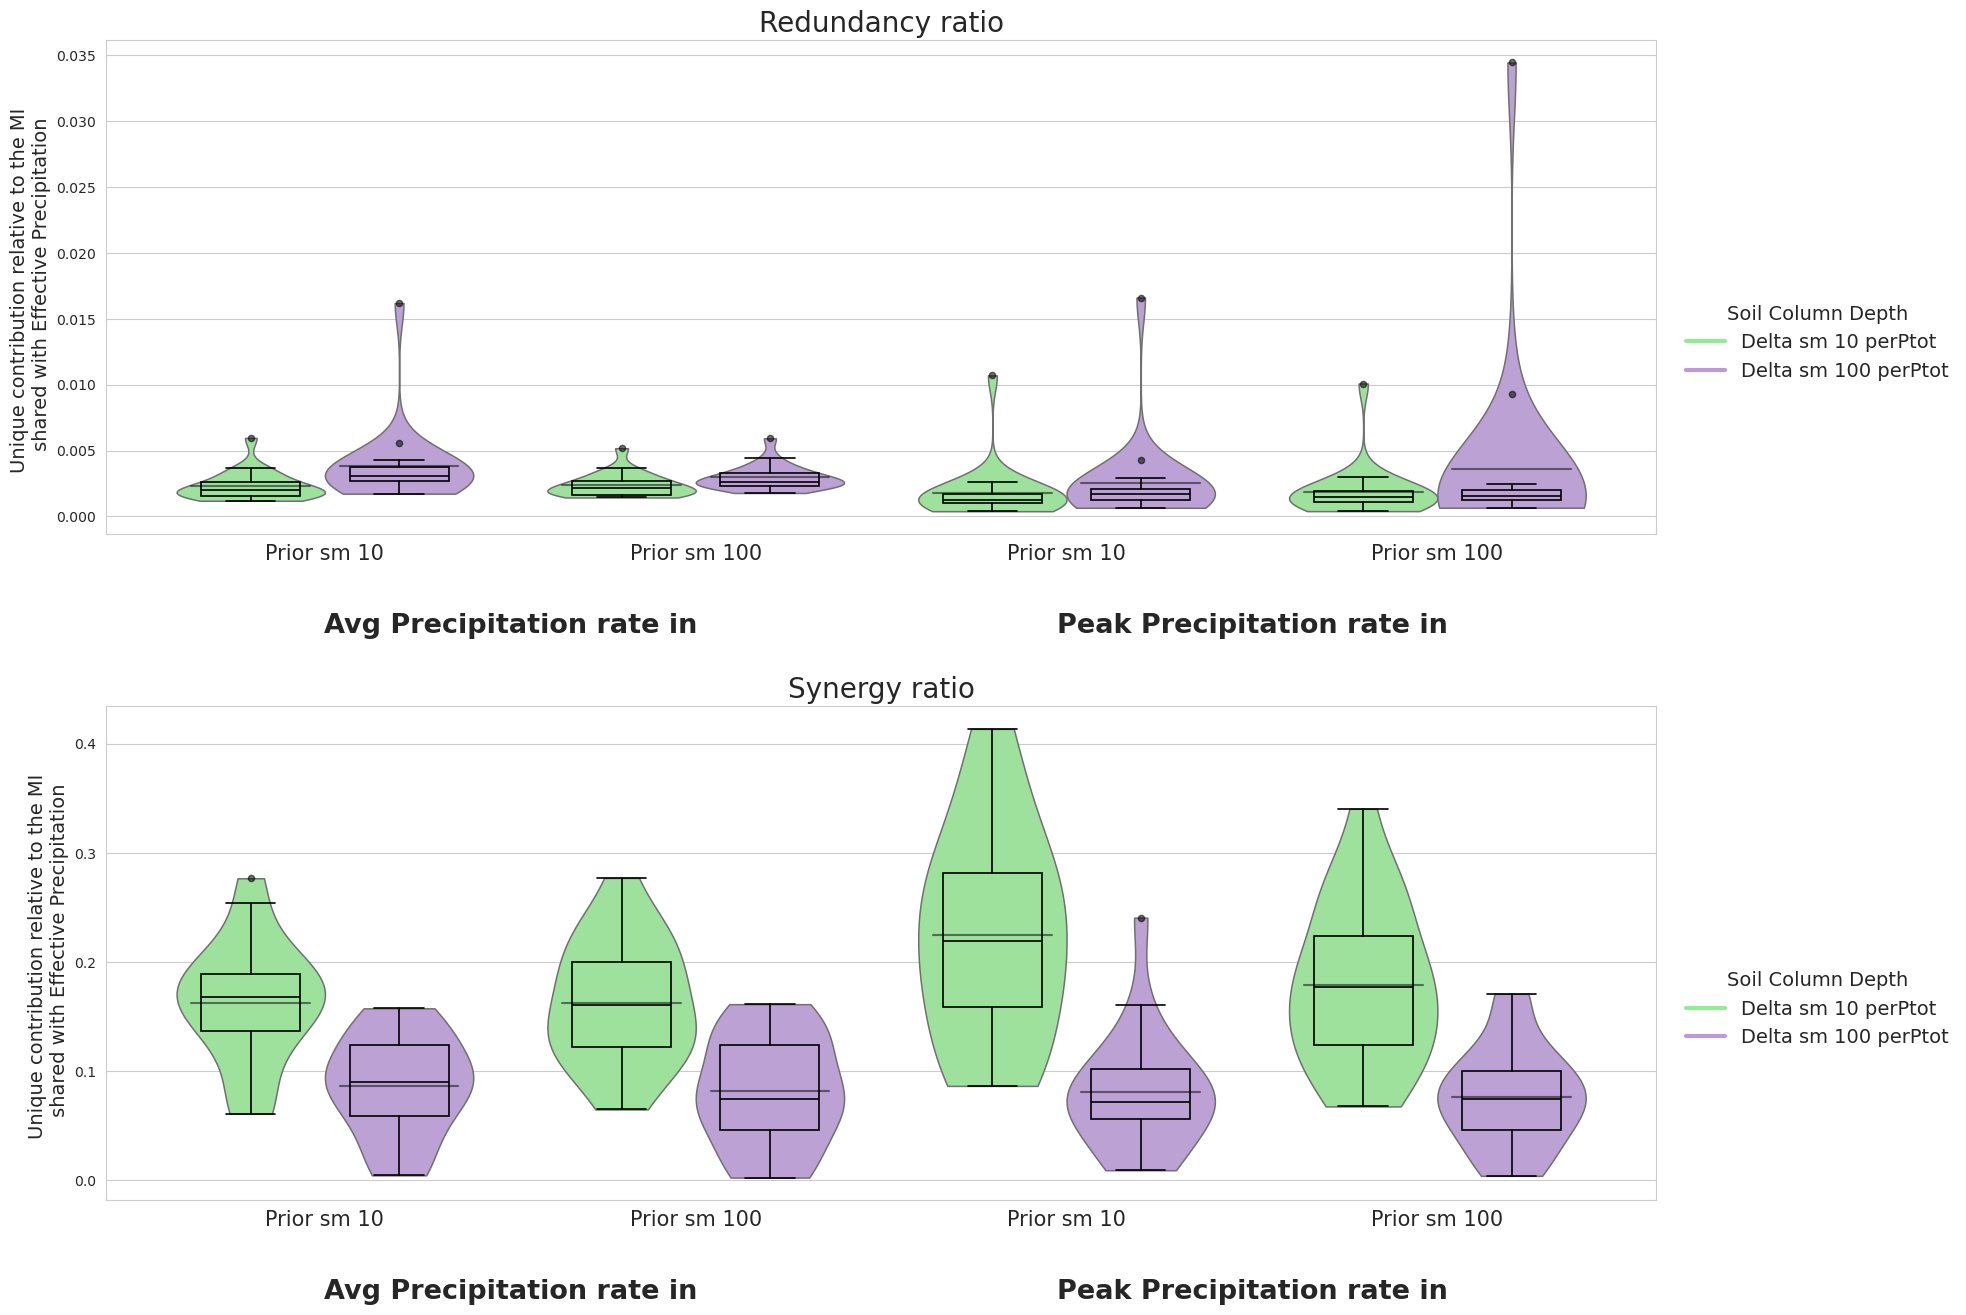

In [85]:
# Visualize redundancy and synergy ratios (perPtot normalized targets) for precipitation and prior soil moisture
redundancy_perptot_base_order = [
    "trivariate_MI_Avg_Precipitation_rate_in_Prior_sm_10",
    "trivariate_MI_Avg_Precipitation_rate_in_Prior_sm_100",
    "trivariate_MI_Peak_Precipitation_rate_in_Prior_sm_10",
    "trivariate_MI_Peak_Precipitation_rate_in_Prior_sm_100",
]
available_perptot_labels = set(
    Partition_values.loc[
        ~Partition_values["MI_label"].str.contains("Median_Precipitation_rate_in")
        & Partition_values["MI_label"].str.contains("_perPtot"),
        "MI_label",
    ]
)

def parse_perptot_components(label: str) -> tuple[str, str]:
    stripped = label.removeprefix("trivariate_MI_")
    if stripped.endswith("_Delta_sm_10_perPtot"):
        stripped = stripped[: -len("_Delta_sm_10_perPtot")]
    elif stripped.endswith("_Delta_sm_100_perPtot"):
        stripped = stripped[: -len("_Delta_sm_100_perPtot")]
    else:
        raise ValueError(f"Unexpected perPtot label format: {label}")
    first_part, prior_suffix = stripped.rsplit("_Prior_sm_", 1)
    first_var = first_part.replace("_", " ")
    prior_label = f"Prior sm {prior_suffix}"
    return first_var, prior_label

selected_perptot_pairs = []
for base in redundancy_perptot_base_order:
    label_10 = f"{base}_Delta_sm_10_perPtot"
    label_100 = f"{base}_Delta_sm_100_perPtot"
    if label_10 in available_perptot_labels and label_100 in available_perptot_labels:
        selected_perptot_pairs.append((label_10, label_100))

if not selected_perptot_pairs:
    raise ValueError("No perPtot Partition_values labels found for redundancy/synergy visualization.")

group_meta: dict[str, tuple[str, str]] = {}
group_keys: list[str] = []
for label_10, label_100 in selected_perptot_pairs:
    first_var, prior_label = parse_perptot_components(label_10)
    key = f"{first_var}__{prior_label}"
    group_meta[key] = (first_var, prior_label)
    group_keys.append(key)

metrics = ["Redundancy_zratio", "Synergistic_ratio"]
perptot_plot_df = (
    Partition_values.loc[
        Partition_values["MI_label"].isin([label for pair in selected_perptot_pairs for label in pair]),
        ["Station", "MI_label", *metrics],
    ].copy()
)

perptot_plot_df["delta_depth"] = perptot_plot_df["MI_label"].apply(
    lambda label: "Delta_sm_100_perPtot" if "Delta_sm_100_perPtot" in label else "Delta_sm_10_perPtot"
)
perptot_plot_df["first_variable"] = perptot_plot_df["MI_label"].apply(lambda label: parse_perptot_components(label)[0])
perptot_plot_df["prior_label"] = perptot_plot_df["MI_label"].apply(lambda label: parse_perptot_components(label)[1])
perptot_plot_df["plot_group_key"] = perptot_plot_df["first_variable"] + "__" + perptot_plot_df["prior_label"]
perptot_plot_df["plot_group"] = pd.Categorical(perptot_plot_df["plot_group_key"], categories=group_keys, ordered=True)
perptot_plot_df = perptot_plot_df[perptot_plot_df["plot_group"].notna()].copy()
perptot_plot_df["plot_group"] = perptot_plot_df["plot_group"].cat.remove_unused_categories()
perptot_plot_df = perptot_plot_df.sort_values("plot_group")

if perptot_plot_df.empty:
    raise ValueError("No perPtot Partition_values remained after filtering for redundancy/synergy visualization.")

group_order = list(perptot_plot_df["plot_group"].cat.categories)

metric_long = perptot_plot_df.melt(
    id_vars=["Station", "MI_label", "delta_depth", "first_variable", "prior_label", "plot_group_key", "plot_group"],
    value_vars=metrics,
    var_name="metric_name",
    value_name="ratio_value",
)

metric_label_map = {
    "Redundancy_zratio": "Redundancy ratio",
    "Synergistic_ratio": "Synergy ratio",
}
metric_order = [metric_label_map[name] for name in metrics]
metric_long["metric_label"] = metric_long["metric_name"].map(metric_label_map)
metric_long = metric_long.dropna(subset=["ratio_value"])
metric_long["metric_label"] = pd.Categorical(metric_long["metric_label"], categories=metric_order, ordered=True)
metric_long["plot_group"] = pd.Categorical(metric_long["plot_group"], categories=group_order, ordered=True)
metric_long = metric_long.sort_values(["metric_label", "plot_group"])

palette_map = {
    "Delta_sm_10_perPtot": "#92ec92",
    "Delta_sm_100_perPtot": "#bc98dd",
}
hue_order = ["Delta_sm_10_perPtot", "Delta_sm_100_perPtot"]

sns.set_style("whitegrid")
fig, axes = plt.subplots(len(metric_order), 1, figsize=(20,20))
axes = np.atleast_1d(axes)

violin_width = 0.8
n_levels = len(hue_order)
box_width = violin_width / (n_levels + 1)
line_half_width = box_width * 0.6

from collections import Counter

base_counts = Counter(group_meta[key][0] for key in group_order)
tick_labels = [group_meta[key][1] for key in group_order]

for ax, metric_label in zip(axes, metric_order):
    subset = metric_long[metric_long["metric_label"] == metric_label]
    if subset.empty:
        ax.set_visible(False)
        continue

    sns.violinplot(
        data=subset,
        x="plot_group",
        y="ratio_value",
        order=group_order,
        hue="delta_depth",
        hue_order=hue_order,
        palette=palette_map,
        dodge=True,
        cut=0,
        inner=None,
        linewidth=1.1,
        width=violin_width,
        density_norm="width",
        ax=ax,
    )

    mean_lookup = (
        subset.groupby(["plot_group", "delta_depth"], observed=False)["ratio_value"]
               .mean()
               .to_dict()
    )

    for x_idx, group in enumerate(group_order):
        for level_idx, level in enumerate(hue_order):
            group_subset = subset[(subset["plot_group"] == group) & (subset["delta_depth"] == level)]
            if group_subset.empty:
                continue

            offset = (-0.5 + (level_idx + 0.5) / n_levels) * violin_width
            center = x_idx + offset

            bp = ax.boxplot(
                group_subset["ratio_value"],
                positions=[center],
                widths=box_width,
                patch_artist=True,
                manage_ticks=False,
                showcaps=True,
                boxprops={"facecolor": "none", "edgecolor": "black", "linewidth": 1.2},
                whiskerprops={"linewidth": 1.2, "color": "black"},
                capprops={"linewidth": 1.2, "color": "black"},
                medianprops={"linewidth": 1.2, "color": "black"},
                flierprops={"marker": "o", "markersize": 4.5, "markerfacecolor": "black", "markeredgecolor": "black", "alpha": 0.55},
            )
            for element in ["whiskers", "caps"]:
                for artist in bp[element]:
                    artist.set(color="black", linewidth=1.2)

            mean_val = mean_lookup.get((group, level))
            if mean_val is not None:
                ax.plot(
                    [center - line_half_width, center + line_half_width],
                    [mean_val, mean_val],
                    color="black",
                    linewidth=1.5,
                    alpha=0.5,
                )

    if ax.legend_ is not None:
        ax.legend_.remove()

    ax.set_xticks(range(len(group_order)))
    ax.set_xticklabels(tick_labels, rotation=0, ha="center", fontsize= 15)
    label_fontsize = ax.get_xticklabels()[0].get_fontsize() if ax.get_xticklabels() else plt.rcParams.get("font.size", 10)

    for base, count in base_counts.items():
        positions = [idx for idx, key in enumerate(group_order) if group_meta[key][0] == base]
        if not positions:
            continue
        midpoint = sum(positions) / len(positions)
        ax.text(
            midpoint,
            -0.16,
            base,
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="top",
            fontsize=label_fontsize * 1.3,
            fontweight="bold",
        )

    ax.set_title(metric_label, fontsize=20)
    ax.set_xlabel("")

axes[0].set_ylabel("Unique contribution relative to the MI \n shared with Effective Precipitation", fontsize =14)
axes[1].set_ylabel("Unique contribution relative to the MI \n shared with Effective Precipitation", fontsize =14)

legend_handles = [
    plt.Line2D([0], [0], color=palette_map[key], lw=3, label=key.replace("_", " "))
    for key in hue_order
]


axes[0].legend(handles=legend_handles, title="Soil Column Depth", title_fontsize =14, fontsize =14, frameon=False, bbox_to_anchor = (1.2, 0.5))
axes[1].legend(handles=legend_handles, title="Soil Column Depth", title_fontsize =14, fontsize =14, frameon=False, bbox_to_anchor = (1.2, 0.5))

fig.subplots_adjust(bottom=0.3, hspace=0.35)
plt.show()
